In [105]:

import pandas as pd



se importa la libreria, quiero poner paso a paso.

In [106]:
df = pd.read_csv('/datasets/games.csv')

se debe leer la base de datos usando pandas. en todo caso el DataFrame se llama como es comun  df... asi lo llamaremos en adelante para entenderlo. 

In [107]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  object 
 1   Platform         16715 non-null  object 
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  object 
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  object 
 10  Rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB


es importante imprimir un info para saber como estan  los datos y como puedo cuadrarlos para trabajarlos dutrante el total del ejercicio. 

In [108]:
df.columns = df.columns.str.lower().str.strip()

despues de imprimir el nombre de las columnas, y darnos cuenta que hay algunas en mayusculas, y no sabemos si hay espacios iniciando y terminando que más adelante en el codigo podria causarnos resultados alterados, por eso el codigo siguiente busca poner todo en minuscula y eliminar los espacios, de tenerlos, y que queden todos iguales. 

In [109]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16713 non-null  object 
 1   platform         16715 non-null  object 
 2   year_of_release  16446 non-null  float64
 3   genre            16713 non-null  object 
 4   na_sales         16715 non-null  float64
 5   eu_sales         16715 non-null  float64
 6   jp_sales         16715 non-null  float64
 7   other_sales      16715 non-null  float64
 8   critic_score     8137 non-null   float64
 9   user_score       10014 non-null  object 
 10  rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB


imprime de nuevo el info para saber como quedaron en realidad y verificar si quedaron los cambuos que se ordenaron en el codigo pasado. 

In [110]:
df.columns

Index(['name', 'platform', 'year_of_release', 'genre', 'na_sales', 'eu_sales', 'jp_sales', 'other_sales', 'critic_score', 'user_score', 'rating'], dtype='object')

es lo mismo que se ve arriba, pero me parece buena practica imprimir el nombre de las solas columnas, en este punto podriamos tener claro de todo lo que se asume como columna, en mi caso me parece oportuno para mirar si se crearon columnas duplicadas que podrian entorpecer el codigo más adelante. 

In [111]:
df.head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


Me parece importante esto para entender la estructura de los datos y como se presenta, aunque con un numero grande de datos es muy poco lo que se logra mirar... pero para mi manera de entender las cosas, es importante tener esa impresion. en este caso lo utilice imprimiendo datos y todas sus columnas, y despues solo imprimí 5 para no hacer tan extenzo el codigo.

In [112]:
df['year_of_release'].unique()


array([2006., 1985., 2008., 2009., 1996., 1989., 1984., 2005., 1999.,
       2007., 2010., 2013., 2004., 1990., 1988., 2002., 2001., 2011.,
       1998., 2015., 2012., 2014., 1992., 1997., 1993., 1994., 1982.,
       2016., 2003., 1986., 2000.,   nan, 1995., 1991., 1981., 1987.,
       1980., 1983.])

con esta impresion logramos ver los valores unicos de los años, me llama la atencion que 'year_of_release' sea float y no int. teniendo en cuenta que los años son numeros i¿enteros. en la literatura marca que tenerlos en int me quitaria los nan mientras que si los transformo en Int si los podria asumir aun.  

In [113]:
df['year_of_release'] = df['year_of_release'].astype('Int64')
df.info()
conteo_por_año = df['year_of_release'].value_counts(dropna=False).sort_index()

print(conteo_por_año)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16713 non-null  object 
 1   platform         16715 non-null  object 
 2   year_of_release  16446 non-null  Int64  
 3   genre            16713 non-null  object 
 4   na_sales         16715 non-null  float64
 5   eu_sales         16715 non-null  float64
 6   jp_sales         16715 non-null  float64
 7   other_sales      16715 non-null  float64
 8   critic_score     8137 non-null   float64
 9   user_score       10014 non-null  object 
 10  rating           9949 non-null   object 
dtypes: Int64(1), float64(5), object(5)
memory usage: 1.4+ MB
1980       9
1981      46
1982      36
1983      17
1984      14
1985      14
1986      21
1987      16
1988      15
1989      17
1990      16
1991      41
1992      43
1993      62
1994     121
1995     219
1996     263
1997     2

decidi cambiar el tipo de dato que tiene la columna 'year_of_release' pues como es el año se tiene en cuenta que no hay años decimales... por eso se podria cambiar, adicional que no tenemos datos
Con el anterior codigo me doy cuenta como se distribuyen los datos en cada uno de los años... tenia la duda que el crecimiento de los reportes fuera proporcional en el tiempo, pero mitrando la distribucion parece no tener una distribucion caracteristica. pense que se podria tratar algun nuevo item que fue determinado con el tiempo osea que hasta un año especifico se empezara a medir. pero vemos que la distribucion es pareja y no hay manera de mirar si mis dudas son acertadas, aunque el hecho de que los valores se encuentren en todos los años que se evaluan (desde 1980 hasta 2016) tener datos en todos los años me despeja esta duda.  

In [114]:
df.info()
print(df['critic_score'].unique())
df['critic_score'].value_counts(dropna=False)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16713 non-null  object 
 1   platform         16715 non-null  object 
 2   year_of_release  16446 non-null  Int64  
 3   genre            16713 non-null  object 
 4   na_sales         16715 non-null  float64
 5   eu_sales         16715 non-null  float64
 6   jp_sales         16715 non-null  float64
 7   other_sales      16715 non-null  float64
 8   critic_score     8137 non-null   float64
 9   user_score       10014 non-null  object 
 10  rating           9949 non-null   object 
dtypes: Int64(1), float64(5), object(5)
memory usage: 1.4+ MB
[76. nan 82. 80. 89. 58. 87. 91. 61. 97. 95. 77. 88. 83. 94. 93. 85. 86.
 98. 96. 90. 84. 73. 74. 78. 92. 71. 72. 68. 62. 49. 67. 81. 66. 56. 79.
 70. 59. 64. 75. 60. 63. 69. 50. 25. 42. 44. 55. 48. 57. 29. 47. 65. 54.
 20. 53. 37.

NaN     8578
70.0     256
71.0     254
75.0     245
78.0     240
        ... 
29.0       3
21.0       1
22.0       1
13.0       1
17.0       1
Name: critic_score, Length: 83, dtype: int64

In [115]:
nan_por_año = (
    df[df['critic_score'].isna()]
    .groupby('year_of_release')
    .size()
    .sort_values(ascending=False)
)

print(nan_por_año)

year_of_release
2009    775
2010    755
2008    712
2011    636
2007    505
2006    386
2015    381
1998    351
2012    332
2014    320
1999    299
2005    284
1997    272
2013    271
2016    270
1996    255
1995    219
2000    207
2002    202
2004    201
2003    190
2001    156
1994    120
1993     62
1981     46
1992     42
1991     41
1982     36
1986     21
1989     17
1983     17
1990     16
1987     16
1988     14
1984     14
1985     13
1980      9
dtype: int64


con esta agrupacion  quiero saber si hay años que no tienen critical_score, que se deban tener en cuenta, pero en este punto solo se mira una distribucion de los valores nan para critic_score al paso de los años... ahora quiero hacer un codigo que me diga estos valores a cuanto corresponden porcentuaslmente de los juegos que se lanzaron en ese año en especifico. 

In [116]:
total_juegos_año = df.groupby('year_of_release').size()

# Número de juegos sin critic_score por año
nan_critic_año = df.groupby('year_of_release')['critic_score'].apply(
    lambda x: x.isna().sum()
)

# Crear tabla resumen
resumen_critic = pd.DataFrame({
    'total_juegos': total_juegos_año,
    'critic_score_nan': nan_critic_año
})

# Calcular el porcentaje de valores ausentes
resumen_critic['porcentaje_nan'] = (
    resumen_critic['critic_score_nan'] /
    resumen_critic['total_juegos'] * 100
).round(2)

# Ordenar por año
resumen_critic = resumen_critic.sort_index()

display(resumen_critic)

,total_juegos,critic_score_nan,porcentaje_nan
year_of_release,,,
1980,9,9,100.00
1981,46,46,100.00
1982,36,36,100.00
1983,17,17,100.00
1984,14,14,100.00
1985,14,13,92.86
1986,21,21,100.00
1987,16,16,100.00
1988,15,14,93.33


con la ayuda de la IA para la generacion del codigo, creo que esta tabla es muy importante porque queria determinar si hay años en los que el parametro 'critic_score' no fue tenido en cuenta... y me doy cuenta que en los primeros añois simplemente el valor 'critic_score' no era medido, por eso seria un error comparar el valor de 'critic_score' de todos los juegos de nuestro DataFrame pues no existe valor significativo para determinar antes del año 2000 los valores de 'critic_score'.

In [117]:

conteo_critic_score = df['critic_score'].value_counts(dropna=False)

print(conteo_critic_score.sort_values(ascending=False))


NaN     8578
70.0     256
71.0     254
75.0     245
78.0     240
        ... 
29.0       3
21.0       1
22.0       1
13.0       1
17.0       1
Name: critic_score, Length: 83, dtype: int64


conteo_critic_score, lo cree para el analisis de la misma manera que se hizo con el anterior, en este caso no quise ordenarlo teniendo en cuenta la calificacion sino las veces que se repite el evento, esto con el animo de determinar y poder comparar como los valores NaN serian superiores a los de cualquier calificacion... osea teniendo en cuenta las posibles calificaciones se presentan puntuaciones entre 1 (calificacion de 17) y 256 veces (calificacion 70.0) y se compara con el numero de veces que se repiten los valores NaN igual a 8578 repeticiones. 

In [118]:
df['user_score'].value_counts(dropna=False)

NaN    6701
tbd    2424
7.8     324
8       290
8.2     282
       ... 
1.3       2
0.2       2
2.3       2
9.7       1
0         1
Name: user_score, Length: 97, dtype: int64

In [119]:
# Total de juegos lanzados por año
total_juegos = df.groupby('year_of_release').size()

# Crear indicadores para cada tipo de valor
es_nan = df['user_score'].isna()
es_tbd = df['user_score'].astype(str).str.strip().str.upper().eq('TBD')
es_numerico = ~es_nan & ~es_tbd

# Contar los valores por año
resumen_user = pd.DataFrame({
    'total_juegos': total_juegos,
    'valores_nan': df[es_nan].groupby('year_of_release').size(),
    'valores_tbd': df[es_tbd].groupby('year_of_release').size(),
    'valores_numericos': df[es_numerico].groupby('year_of_release').size()
}).fillna(0).astype(int)

# Calcular los porcentajes respecto al total de juegos de cada año
resumen_user['porcentaje_nan'] = (
    resumen_user['valores_nan'] / resumen_user['total_juegos'] * 100
).round(2)

resumen_user['porcentaje_tbd'] = (
    resumen_user['valores_tbd'] / resumen_user['total_juegos'] * 100
).round(2)

resumen_user['porcentaje_numericos'] = (
    resumen_user['valores_numericos'] / resumen_user['total_juegos'] * 100
).round(2)

# Sumar los porcentajes
resumen_user['suma_porcentajes'] = (
    resumen_user['porcentaje_nan']
    + resumen_user['porcentaje_tbd']
    + resumen_user['porcentaje_numericos']
).round(2)

# Ordenar por año y mostrar resultados
resumen_user = resumen_user.sort_index()

display(resumen_user)

,total_juegos,valores_nan,valores_tbd,valores_numericos,porcentaje_nan,porcentaje_tbd,porcentaje_numericos,suma_porcentajes
year_of_release,,,,,,,,
1980,9,9,0,0,100.00,0.00,0.00,100.00
1981,46,46,0,0,100.00,0.00,0.00,100.00
1982,36,36,0,0,100.00,0.00,0.00,100.00
1983,17,17,0,0,100.00,0.00,0.00,100.00
1984,14,14,0,0,100.00,0.00,0.00,100.00
1985,14,13,0,1,92.86,0.00,7.14,100.00
1986,21,21,0,0,100.00,0.00,0.00,100.00
1987,16,16,0,0,100.00,0.00,0.00,100.00
1988,15,14,0,1,93.33,0.00,6.67,100.00


con 'user_score' me doy cuenta que aparte de los valores NaN, se encuentra valores tbd.
con el anterior codigo me doy cuenta que los valores nan igualmente son recurrentes con un alto porcentaje de insidencia para años anteriores al 2000, en adelante se presentan de manera esporadica pero alcanzando a casi la mitad de los valores totales que se obtienen en esta columna, y se asume que es un comportamienti un poco normal. los valores tdb, igualmente empiuezan a aparecer para el año 2000 y la presencia es mucho menos a la de valores nan. este analisis es buenn porque permite ser objetivo cuando se quiera comparar los valores de user_score, año tras año, pues en realidad en años anteriores al 2000 es muy poco frecuente que se encuentren valores al respecto.

teniendo en cuenta que en la tabla anterior no se mostro los valores porcentuales para el año 2016, y teniendo en cuenta que para ese año hay un gran numero de valores, decidi hacer un codigo para nococer lo que esta pasando con eso.

In [120]:
# Identificar cada tipo de valor
es_nan = df['user_score'].isna()

es_tbd = (
    df['user_score']
    .astype('string')
    .str.strip()
    .str.upper()
    .eq('TBD')
    .fillna(False)
)

es_numerico = pd.to_numeric(
    df['user_score'],
    errors='coerce'
).notna()

# Resumir por año
resumen_user = df.groupby('year_of_release').size().to_frame(
    'total_juegos'
)

resumen_user['valores_nan'] = (
    df[es_nan].groupby('year_of_release').size()
)

resumen_user['valores_tbd'] = (
    df[es_tbd].groupby('year_of_release').size()
)

resumen_user['valores_numericos'] = (
    df[es_numerico].groupby('year_of_release').size()
)

# Los años sin registros de alguna categoría reciben cero
columnas_conteo = [
    'valores_nan', 'valores_tbd', 'valores_numericos'
]
resumen_user[columnas_conteo] = (
    resumen_user[columnas_conteo].fillna(0).astype(int)
)

# Calcular porcentajes
for columna in columnas_conteo:
    nombre_porcentaje = columna.replace('valores_', 'porcentaje_')
    resumen_user[nombre_porcentaje] = (
        resumen_user[columna] / resumen_user['total_juegos'] * 100
    ).round(2)

resumen_user['suma_porcentajes'] = resumen_user[
    ['porcentaje_nan', 'porcentaje_tbd', 'porcentaje_numericos']
].sum(axis=1).round(2)

display(resumen_user)


,total_juegos,valores_nan,valores_tbd,valores_numericos,porcentaje_nan,porcentaje_tbd,porcentaje_numericos,suma_porcentajes
year_of_release,,,,,,,,
1980,9,9,0,0,100.00,0.00,0.00,100.00
1981,46,46,0,0,100.00,0.00,0.00,100.00
1982,36,36,0,0,100.00,0.00,0.00,100.00
1983,17,17,0,0,100.00,0.00,0.00,100.00
1984,14,14,0,0,100.00,0.00,0.00,100.00
1985,14,13,0,1,92.86,0.00,7.14,100.00
1986,21,21,0,0,100.00,0.00,0.00,100.00
1987,16,16,0,0,100.00,0.00,0.00,100.00
1988,15,14,0,1,93.33,0.00,6.67,100.00


In [121]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16713 non-null  object 
 1   platform         16715 non-null  object 
 2   year_of_release  16446 non-null  Int64  
 3   genre            16713 non-null  object 
 4   na_sales         16715 non-null  float64
 5   eu_sales         16715 non-null  float64
 6   jp_sales         16715 non-null  float64
 7   other_sales      16715 non-null  float64
 8   critic_score     8137 non-null   float64
 9   user_score       10014 non-null  object 
 10  rating           9949 non-null   object 
dtypes: Int64(1), float64(5), object(5)
memory usage: 1.4+ MB


teniendo en cuenta que 'user_score' es importante para los calculos que en adelante se hagan, se creara una nueva columna en la que los valores ausentes continuen como ausentes y los valores tbd sean convertidos en ausentes, de esa manera para efecto de lso calculos se podria tomar la columna nueva, en este caso 'user_score_sin_tbd', sin oerder la distincion de los datos marcados como TBD que mas adelante podrian servir. no quiero perder esa informacion sin saber que tan iportante podra ser esta distincion en datos más adelante. 

In [122]:
import numpy as np

In [123]:
# Crear una nueva columna con las puntuaciones numéricas
df['user_score_sin_tbd'] = pd.to_numeric(
    df['user_score'].replace('TBD', np.nan),
    errors='coerce'
)

# Comprobar el resultado
df[['user_score', 'user_score_sin_tbd']].info()

# Mostrar algunos ejemplos
display(df[['user_score', 'user_score_sin_tbd']].head(15))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 2 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   user_score          10014 non-null  object 
 1   user_score_sin_tbd  7590 non-null   float64
dtypes: float64(1), object(1)
memory usage: 261.3+ KB


,user_score,user_score_sin_tbd
0,8,8.0
1,NaN,NaN
2,8.3,8.3
3,8,8.0
4,NaN,NaN
5,NaN,NaN
6,8.5,8.5
7,6.6,6.6
8,8.4,8.4
9,NaN,NaN


In [124]:

print('NaN originales:', df['user_score'].isna().sum())

print(
    'TBD originales:',
    df['user_score'].astype('string').str.strip().str.upper().eq('TBD').sum()
)

print(
    'Puntuaciones numéricas:',
    df['user_score_sin_tbd'].notna().sum()
)

print(
    'NaN en la nueva columna:',
    df['user_score_sin_tbd'].isna().sum()
)

NaN originales: 6701
TBD originales: 2424
Puntuaciones numéricas: 7590
NaN en la nueva columna: 9125


con este ajuste la columna 'user_score_sin_tbd' parece haber aumentado los valores ausentes, y eso pasa porque los valores TBD en la columna ascendente no incluia dichos valores como ausentes... ahora si, y garantizamos que los datos totales de 'user_score_sin_tbd' son numericos aceptables para analisis.

In [125]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   name                16713 non-null  object 
 1   platform            16715 non-null  object 
 2   year_of_release     16446 non-null  Int64  
 3   genre               16713 non-null  object 
 4   na_sales            16715 non-null  float64
 5   eu_sales            16715 non-null  float64
 6   jp_sales            16715 non-null  float64
 7   other_sales         16715 non-null  float64
 8   critic_score        8137 non-null   float64
 9   user_score          10014 non-null  object 
 10  rating              9949 non-null   object 
 11  user_score_sin_tbd  7590 non-null   float64
dtypes: Int64(1), float64(6), object(5)
memory usage: 1.5+ MB


In [126]:
print(df['rating'].unique())

print(df['rating'].value_counts(dropna=False))


['E' nan 'M' 'T' 'E10+' 'K-A' 'AO' 'EC' 'RP']
NaN     6766
E       3990
T       2961
M       1563
E10+    1420
EC         8
K-A        3
RP         3
AO         1
Name: rating, dtype: int64


In [127]:
# Crear una columna auxiliar para identificar los valores ausentes
df['rating_grupo'] = df['rating'].fillna('NaN')

# Contar las categorías por año
rating_conteo = pd.crosstab(
    df['year_of_release'],
    df['rating_grupo']
)

# Incorporar todos los años entre 1980 y 2016
todos_los_años = range(1980, 2017)

rating_conteo = rating_conteo.reindex(
    todos_los_años,
    fill_value=0
)

# Calcular el total de juegos lanzados por año
rating_conteo['total_juegos'] = (
    df.groupby('year_of_release').size()
      .reindex(todos_los_años, fill_value=0)
)

# Calcular los porcentajes por año
columnas_rating = [
    columna for columna in rating_conteo.columns
    if columna != 'total_juegos'
]

rating_porcentajes = rating_conteo[columnas_rating].div(
    rating_conteo['total_juegos'].replace(0, np.nan),
    axis=0
).mul(100).round(2)

# Añadir el total de juegos
rating_porcentajes.insert(
    0,
    'total_juegos',
    rating_conteo['total_juegos']
)

display(rating_porcentajes)


rating_grupo,total_juegos,AO,E,E10+,EC,K-A,M,NaN,RP,T
year_of_release,,,,,,,,,,
1980,9,0.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00,0.00
1981,46,0.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00,0.00
1982,36,0.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00,0.00
1983,17,0.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00,0.00
1984,14,0.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00,0.00
1985,14,0.00,0.00,0.00,0.00,0.00,0.00,92.86,0.00,7.14
1986,21,0.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00,0.00
1987,16,0.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00,0.00
1988,15,0.00,0.00,6.67,0.00,0.00,0.00,93.33,0.00,0.00


en el caso de 'rating' la decision es dejarla como Object, pero es imporanre aclarar que hay un marcado comportamiento en valores NaN igualmente para los primeros años.
este datro se tendra en cuenta maa adelante en el analisis, para no sacar conclusiones erroneas. 


In [128]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   name                16713 non-null  object 
 1   platform            16715 non-null  object 
 2   year_of_release     16446 non-null  Int64  
 3   genre               16713 non-null  object 
 4   na_sales            16715 non-null  float64
 5   eu_sales            16715 non-null  float64
 6   jp_sales            16715 non-null  float64
 7   other_sales         16715 non-null  float64
 8   critic_score        8137 non-null   float64
 9   user_score          10014 non-null  object 
 10  rating              9949 non-null   object 
 11  user_score_sin_tbd  7590 non-null   float64
 12  rating_grupo        16715 non-null  object 
dtypes: Int64(1), float64(6), object(6)
memory usage: 1.7+ MB


In [129]:

df['total_sales'] = (df['na_sales'] +df['eu_sales'] + df['jp_sales'] + df['other_sales']
)

In [130]:
df.head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,user_score_sin_tbd,rating_grupo,total_sales
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8,E,8.0,E,82.54
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN,NaN,NaN,40.24
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E,8.3,E,35.52
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80.0,8,E,8.0,E,32.77
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN,NaN,NaN,31.38


para la sumatoria del total de las ventas, se realizo el codigo para la creacion de la columna 'total_sales' que en  adelante tendra los datos del 100% de los valores de ventas, creo que servira muchjo para determinar el impacto total de las ventas de un juego en especifico y proporcionalmente cuando impacta cada region en sus ventas. podria determinar favoritismos por algun tipo de juego y podria orientar las campañas futuras para generar un mayor impacto en ventas o propocionar juegos que podrian ser exito en ventas en un lugar determinado. 

In [131]:
juegos_por_año = (
    df.groupby('year_of_release')['name']
    .count()
    .sort_index()
)

print(juegos_por_año)


year_of_release
1980       9
1981      46
1982      36
1983      17
1984      14
1985      14
1986      21
1987      16
1988      15
1989      17
1990      16
1991      41
1992      43
1993      60
1994     121
1995     219
1996     263
1997     289
1998     379
1999     338
2000     350
2001     482
2002     829
2003     775
2004     762
2005     939
2006    1006
2007    1197
2008    1427
2009    1426
2010    1255
2011    1136
2012     653
2013     544
2014     581
2015     606
2016     502
Name: name, dtype: int64


In [132]:

from scipy.stats import spearmanr

# Contar los juegos registrados en cada año
juegos_por_año = (
    df.groupby('year_of_release')['name']
    .count()
    .sort_index()
)

# Evaluar la relación entre el año y la cantidad de lanzamientos
resultado = spearmanr(
    juegos_por_año.index,
    juegos_por_año.values
)

print(f"Coeficiente de Spearman: {resultado.statistic:.4f}")
print(f"Valor p: {resultado.pvalue:.6f}")

if resultado.pvalue < 0.05:
    print("Existe evidencia estadística de una asociación monotónica.")
else:
    print("No hay evidencia estadística suficiente de una asociación monotónica.")


Coeficiente de Spearman: 0.8698
Valor p: 0.000000
Existe evidencia estadística de una asociación monotónica.


con ayuda de la IA quiero determinar la manera estadistica para soportar que en realidad hay relacion entre los años de lanzamiento y el numero de videojuegos que se lanzaron, ya que era evidente las diferencias, quiero ir un paso más adelante para poder determinar y soportar lo que se ve a simple vista, mas adelante quiero hacer una grafica de disoercion que me permita determinar las diferencias. ahora que con un valor p inferior a 0.05 debo rechazamos la hipotesis nula por lo que se encontró evidencia estadística de una asociación positiva.

In [133]:

from scipy.stats import kruskal

# Definir los períodos de análisis
periodos = {
    '1980-1994': (1980, 1994),
    '1995-2001': (1995, 2001),
    '2002-2011': (2002, 2011),
    '2012-2016': (2012, 2016)
}

# Crear una lista con los conteos anuales de cada período
grupos = []

for nombre, (inicio, fin) in periodos.items():
    grupo = juegos_por_año.loc[inicio:fin]
    grupos.append(grupo.values)

    print(
        f"{nombre}: "
        f"media = {grupo.mean():.2f}, "
        f"mediana = {grupo.median():.2f}, "
        f"años = {len(grupo)}"
    )

# Aplicar la prueba de Kruskal-Wallis
estadistico, valor_p = kruskal(*grupos)

print(f"\nEstadístico H: {estadistico:.4f}")
print(f"Valor p: {valor_p:.6f}")

if valor_p < 0.05:
    print("Se rechaza la hipótesis nula: hay diferencias entre las distribuciones de los períodos.")
else:
    print("No se rechaza la hipótesis nula: no hay evidencia suficiente de diferencias entre los períodos.")


1980-1994: media = 32.40, mediana = 17.00, años = 15
1995-2001: media = 331.43, mediana = 338.00, años = 7
2002-2011: media = 1075.20, mediana = 1071.00, años = 10
2012-2016: media = 577.20, mediana = 581.00, años = 5

Estadístico H: 32.5934
Valor p: 0.000000
Se rechaza la hipótesis nula: hay diferencias entre las distribuciones de los períodos.


Con un nivel de significancia de 0,05, se rechaza la hipótesis nula de igualdad de las distribuciones.
Existe evidencia de diferencias entre las distribuciones de los conteos anuales de los cuatro períodos. 

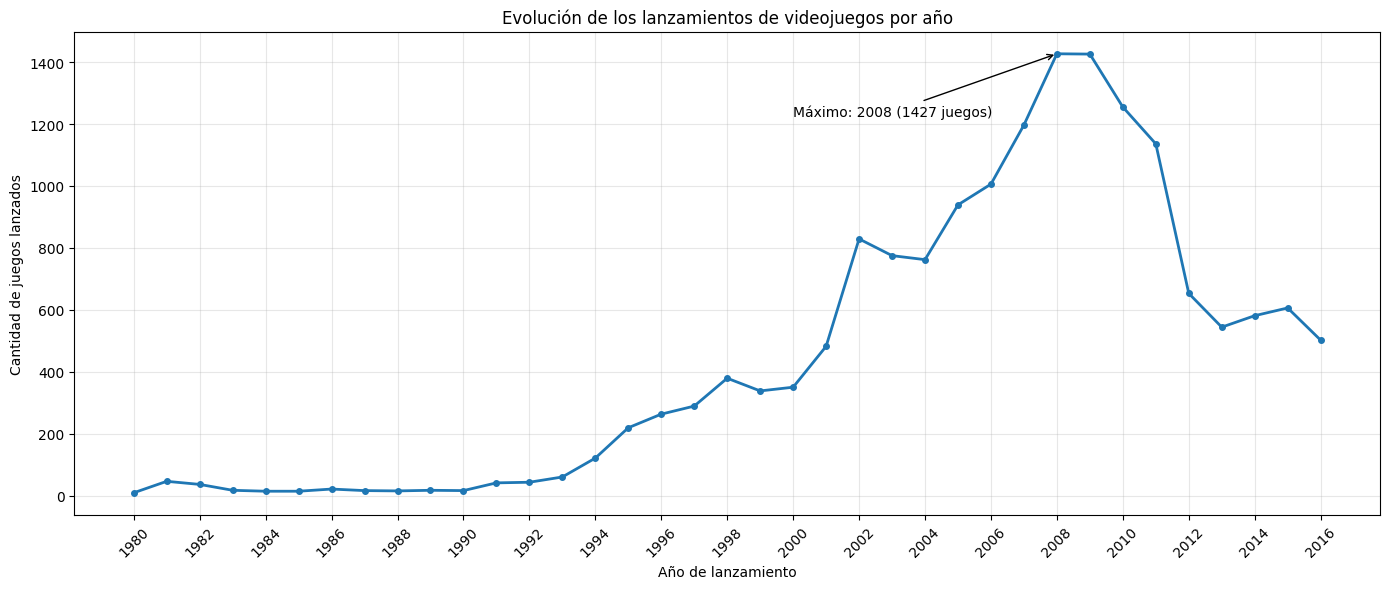

In [134]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    juegos_por_año.index,
    juegos_por_año.values,
    marker='o',
    markersize=4,
    linewidth=2
)

plt.title('Evolución de los lanzamientos de videojuegos por año')
plt.xlabel('Año de lanzamiento')
plt.ylabel('Cantidad de juegos lanzados')

plt.xticks(range(1980, 2017, 2), rotation=45)
plt.grid(True, alpha=0.3)

# Identificar el año con más lanzamientos
año_maximo = juegos_por_año.idxmax()
cantidad_maxima = juegos_por_año.max()

plt.annotate(
    f'Máximo: {año_maximo} ({cantidad_maxima} juegos)',
    xy=(año_maximo, cantidad_maxima),
    xytext=(año_maximo - 8, cantidad_maxima - 200),
    arrowprops=dict(arrowstyle='->')
)

plt.tight_layout()
plt.show()


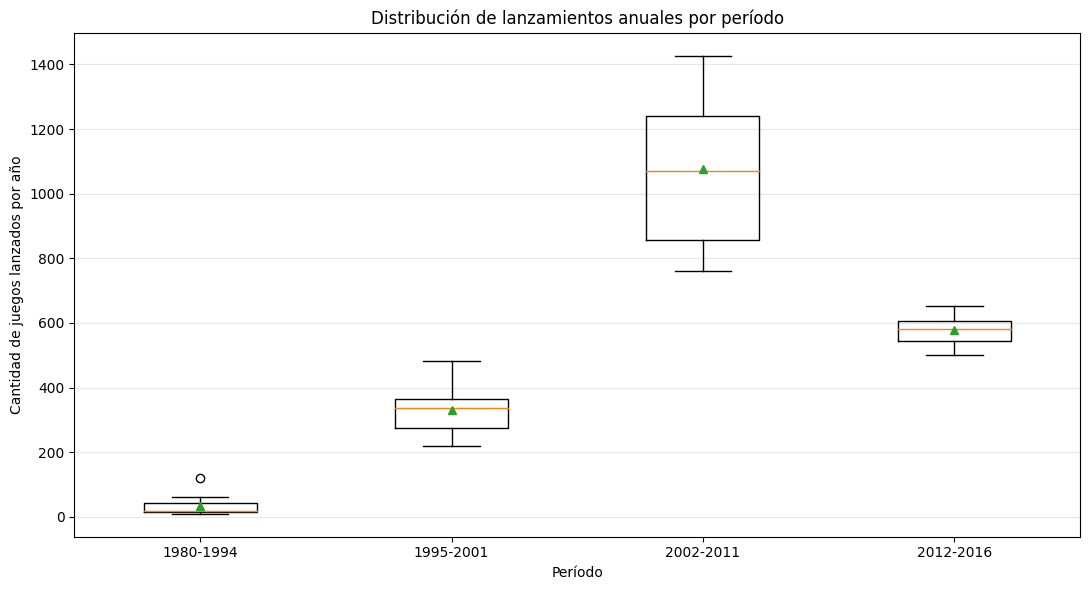

In [135]:

import matplotlib.pyplot as plt

datos_por_periodo = []
etiquetas = []

for nombre, (inicio, fin) in periodos.items():
    datos = juegos_por_año.loc[inicio:fin]
    datos_por_periodo.append(datos.values)
    etiquetas.append(nombre)

plt.figure(figsize=(11, 6))

plt.boxplot(
    datos_por_periodo,
    labels=etiquetas,
    showmeans=True
)

plt.title('Distribución de lanzamientos anuales por período')
plt.xlabel('Período')
plt.ylabel('Cantidad de juegos lanzados por año')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()



In [136]:

for nombre, (inicio, fin) in periodos.items():
    datos = juegos_por_año.loc[inicio:fin]

    q1 = datos.quantile(0.25)
    q3 = datos.quantile(0.75)
    rango_intercuartil = q3 - q1

    limite_inferior = q1 - 1.5 * rango_intercuartil
    limite_superior = q3 + 1.5 * rango_intercuartil

    valores_atipicos = datos[
        (datos < limite_inferior) |
        (datos > limite_superior)
    ]

    print(f"\nPeríodo: {nombre}")
    print(f"Límite inferior: {limite_inferior:.2f}")
    print(f"Límite superior: {limite_superior:.2f}")
    print("Posibles valores atípicos:")
    print(valores_atipicos)



Período: 1980-1994
Límite inferior: -24.25
Límite superior: 81.75
Posibles valores atípicos:
year_of_release
1994    121
Name: name, dtype: int64

Período: 1995-2001
Límite inferior: 143.25
Límite superior: 497.25
Posibles valores atípicos:
Series([], Name: name, dtype: int64)

Período: 2002-2011
Límite inferior: 280.50
Límite superior: 1816.50
Posibles valores atípicos:
Series([], Name: name, dtype: int64)

Período: 2012-2016
Límite inferior: 451.00
Límite superior: 699.00
Posibles valores atípicos:
Series([], Name: name, dtype: int64)


con los anteriores codigos, buscava mostrar la evidencia de los datos pero en realidad nos sirve mejor para saber como se distribuyen los datos de lanzamientos en el transcurso de los años, ya que si bien se ve un incremento marcado en los lanzamoentos, tambien se ve que el crecimiento no es continuo y que se empieza a desacelerar y en un punto a reducir los lanzamientos. es de gran importancia identificar este comportamiento y tenerlo claro para que en el momento del analisis, se tenga en cuenta este comportamenito y no se clncluya erroneamente. en realidad con los codigos y las pruebas estadisticas buscaba familiarizarme con el uso y, desde luego, tener un soporte estadistico para defender la variacion con evidencias. 


In [137]:

# Obtener las plataformas únicas
plataformas_unicas = sorted(df['platform'].dropna().unique())

print("Cantidad de plataformas únicas:", len(plataformas_unicas))
print("\nListado de plataformas:")

for plataforma in plataformas_unicas:
    print(plataforma)


Cantidad de plataformas únicas: 31

Listado de plataformas:
2600
3DO
3DS
DC
DS
GB
GBA
GC
GEN
GG
N64
NES
NG
PC
PCFX
PS
PS2
PS3
PS4
PSP
PSV
SAT
SCD
SNES
TG16
WS
Wii
WiiU
X360
XB
XOne


In [138]:

# Normalizar temporalmente los nombres para detectar posibles duplicados
revision = df[['platform']].drop_duplicates().copy()

revision['platform_normalizada'] = (
    revision['platform']
    .str.strip()
    .str.upper()
)

duplicados = revision[
    revision.duplicated(
        subset='platform_normalizada',
        keep=False
    )
].sort_values('platform_normalizada')

print(duplicados)


Empty DataFrame
Columns: [platform, platform_normalizada]
Index: []


In [139]:
revision.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 31 entries, 0 to 14634
Data columns (total 2 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   platform              31 non-null     object
 1   platform_normalizada  31 non-null     object
dtypes: object(2)
memory usage: 744.0+ bytes


con el anterior codigo queria comprobar si se habia afectado algo con la creacion de la columna 'platform_normalizada' en el df original. 

In [140]:

ventas_por_plataforma = (
    df.groupby('platform')['total_sales']
    .sum()
    .sort_values(ascending=False)
)

print(ventas_por_plataforma)


platform
PS2     1255.77
X360     971.42
PS3      939.65
Wii      907.51
DS       806.12
PS       730.86
GBA      317.85
PS4      314.14
PSP      294.05
PC       259.52
3DS      259.00
XB       257.74
GB       255.46
NES      251.05
N64      218.68
SNES     200.04
GC       198.93
XOne     159.32
2600      96.98
WiiU      82.19
PSV       54.07
SAT       33.59
GEN       30.77
DC        15.95
SCD        1.86
NG         1.44
WS         1.42
TG16       0.16
3DO        0.10
GG         0.04
PCFX       0.03
Name: total_sales, dtype: float64


con el anterior codigo quiero saber como se comportaron las ventas de las diferentes plataformas. cuales vendieron mas que otras, aunque aun no me dejan ver como se comparon las ventas de cada uno, si es positivo saber como se distribuyen las ventas totales. por esto agrupamos por plataformas y sumamos el total de ventas que a su vez el la sumatoria de las ventas de las diferentes regiones. como dato seguido se quiere hacer una grafica que tome el total de las ventas por año de cada plataforma, para saber como se comportaron las ventas. 

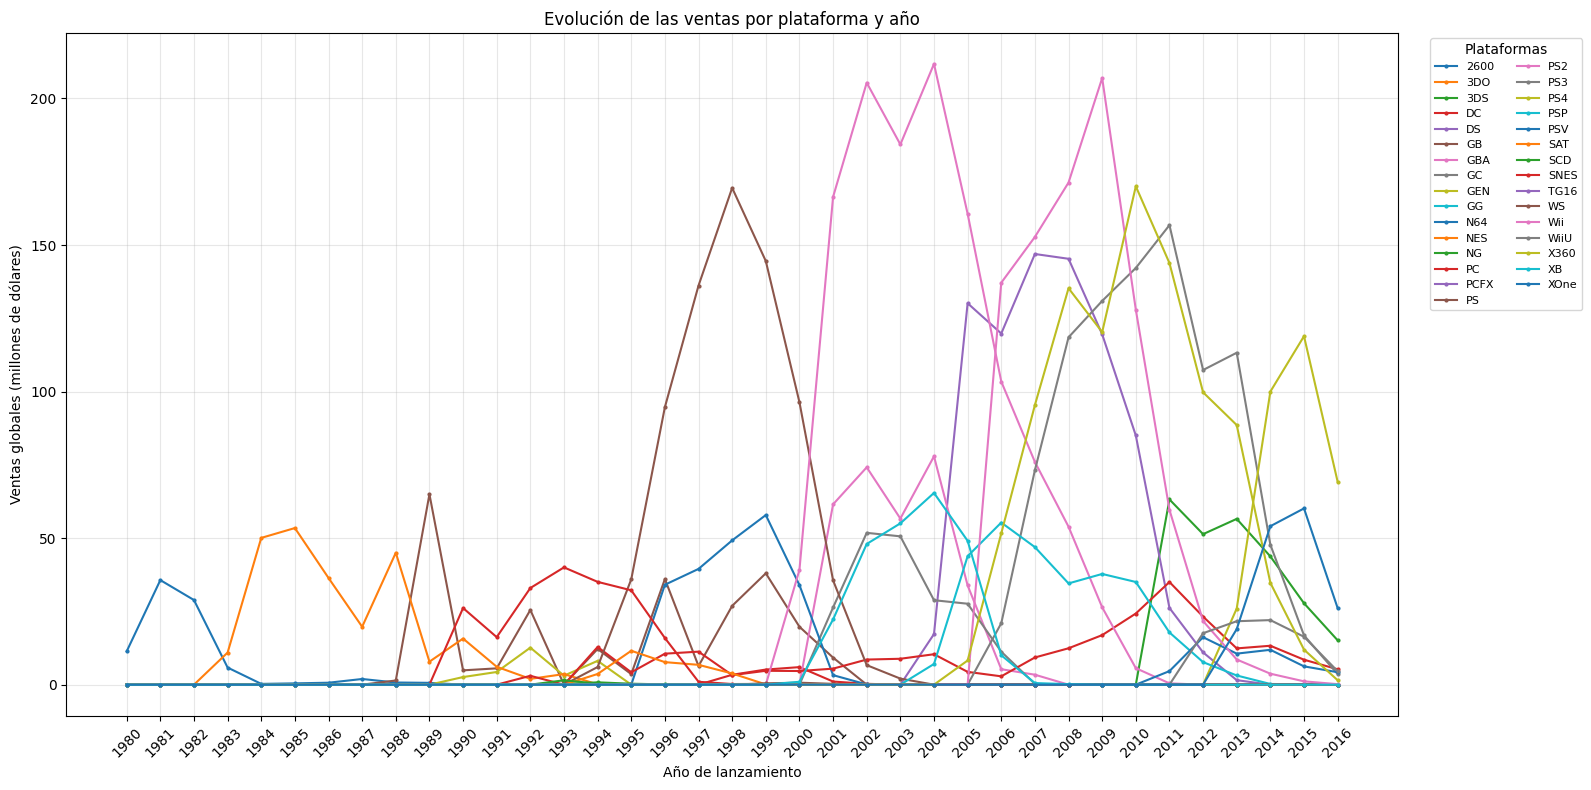

In [141]:

import pandas as pd
import matplotlib.pyplot as plt

# Agrupar las ventas por plataforma y año
ventas_plataforma_año = (
    df.dropna(subset=['year_of_release'])
    .pivot_table(
        index='year_of_release',
        columns='platform',
        values='total_sales',
        aggfunc='sum',
        fill_value=0
    )
    .sort_index()
)

# Graficar la evolución de las ventas de las 31 plataformas
plt.figure(figsize=(16, 8))

for plataforma in ventas_plataforma_año.columns:
    plt.plot(
        ventas_plataforma_año.index,
        ventas_plataforma_año[plataforma],
        marker='o',
        markersize=2,
        linewidth=1.5,
        label=plataforma
    )

plt.title('Evolución de las ventas por plataforma y año')
plt.xlabel('Año de lanzamiento')
plt.ylabel('Ventas globales (millones de dólares)')

plt.xticks(
    ventas_plataforma_año.index.astype(int),
    rotation=45
)

plt.legend(
    title='Plataformas',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    ncol=2,
    fontsize=8
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [142]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Calcular las ventas totales por plataforma
ventas_totales = (
    df.groupby('platform')['total_sales']
    .sum()
    .sort_values(ascending=False)
)

# Transformar las ventas para reducir la asimetría
datos_grupos = np.log1p(ventas_totales).to_frame(name='log_ventas')

# Evaluar diferentes cantidades de grupos
resultados_silueta = {}

for k in range(2, min(9, len(datos_grupos))):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    etiquetas = modelo.fit_predict(datos_grupos)

    resultados_silueta[k] = silhouette_score(
        datos_grupos,
        etiquetas
    )

# Seleccionar la cantidad de grupos con mayor silueta
k_optimo = max(resultados_silueta, key=resultados_silueta.get)

print("Número de plataformas:", len(ventas_totales))
print("\nCoeficiente de silueta por cantidad de grupos:")

for k, puntuacion in resultados_silueta.items():
    print(f"{k} grupos: {puntuacion:.4f}")

print(f"\nCantidad de grupos seleccionada: {k_optimo}")

# Entrenar el modelo definitivo
modelo_final = KMeans(
    n_clusters=k_optimo,
    random_state=42,
    n_init=20
)

ventas_totales_df = ventas_totales.to_frame(name='total_sales')
ventas_totales_df['grupo'] = modelo_final.fit_predict(datos_grupos)

# Ordenar los grupos desde menores hasta mayores ventas promedio
orden_grupos = (
    ventas_totales_df.groupby('grupo')['total_sales']
    .median()
    .sort_values()
    .index
)

mapa_grupos = {
    grupo: posicion + 1
    for posicion, grupo in enumerate(orden_grupos)
}

ventas_totales_df['grupo'] = ventas_totales_df['grupo'].map(mapa_grupos)

print("\nPlataformas clasificadas:")
print(
    ventas_totales_df.sort_values(
        ['grupo', 'total_sales']
    ).to_string()
)


Número de plataformas: 31

Coeficiente de silueta por cantidad de grupos:
2 grupos: 0.7356
3 grupos: 0.6703
4 grupos: 0.7522
5 grupos: 0.7476
6 grupos: 0.7693
7 grupos: 0.7074
8 grupos: 0.7010

Cantidad de grupos seleccionada: 6

Plataformas clasificadas:
          total_sales  grupo
platform                    
PCFX             0.03      1
GG               0.04      1
3DO              0.10      1
TG16             0.16      1
WS               1.42      2
NG               1.44      2
SCD              1.86      2
DC              15.95      3
GEN             30.77      3
SAT             33.59      3
PSV             54.07      4
WiiU            82.19      4
2600            96.98      4
XOne           159.32      5
GC             198.93      5
SNES           200.04      5
N64            218.68      5
NES            251.05      5
GB             255.46      5
XB             257.74      5
3DS            259.00      5
PC             259.52      5
PSP            294.05      5
PS4            314.

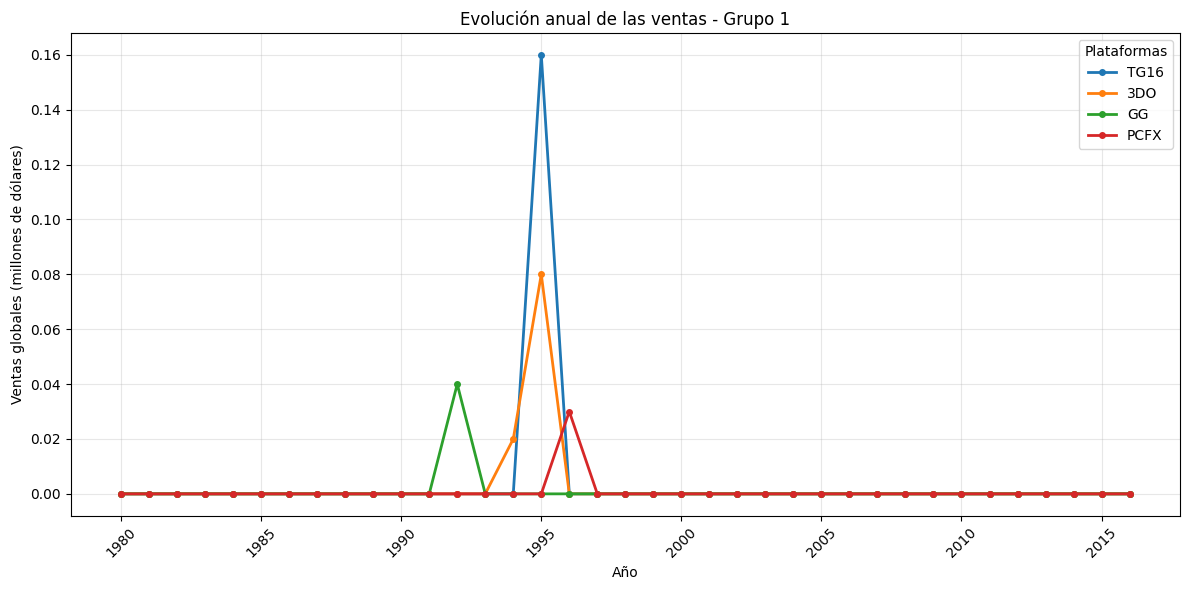

In [143]:

import matplotlib.pyplot as plt

# Identificar las plataformas del grupo 1
plataformas_grupo_1 = ventas_totales_df.index[
    ventas_totales_df['grupo'] == 1
]

# Crear la gráfica
plt.figure(figsize=(12, 6))

for plataforma in plataformas_grupo_1:
    plt.plot(
        ventas_plataforma_año.index,
        ventas_plataforma_año[plataforma],
        marker='o',
        markersize=4,
        linewidth=2,
        label=plataforma
    )

plt.title('Evolución anual de las ventas - Grupo 1')
plt.xlabel('Año')
plt.ylabel('Ventas globales (millones de dólares)')
plt.xticks(rotation=45)

plt.legend(title='Plataformas')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


despues de graficar las ventas de los diferentes paltaformas durante los años, se determino la necesidad de dividir las 31 plataformas observadas en grupos para que el analisis sea mas facil, con ayuda de la IA se determino una prueba para poder dividir en los diferentes grupos, se tuvo en cuenta que la distribucion de las ventas totales en todo el periorod de ciemtpo fuera similar, y se determino que el mejor numerio de grupos para este caso era de 6 grupos, y se procedio a realizar la distribucion, despues se busca graficar cada grupo ya con diferente numero de datos obteniendo que si bien las ventas totales de este gerupo 1 de plataformas es similar en sus medias, el comprtamiento de las mismas podria ser diferente, ya que unas pueden obedecer a ventas concentradas en una peqieña ventana de tiempo y otras a las ventas regulares dutrante varios años. pero eso quiero verlo en una tabla para saber si esas plataformas que mostraron picos, en realidad no reportan ventas afuera de los picos. 

In [144]:


# Obtener las plataformas del grupo 1
plataformas_grupo_1 = ventas_totales_df.index[
    ventas_totales_df['grupo'] == 1
].tolist()

# Agrupar los registros originales por plataforma y año
ventas_reales_grupo_1 = (
    df.dropna(subset=['year_of_release'])
    .loc[lambda datos: datos['platform'].isin(plataformas_grupo_1)]
    .groupby(['platform', 'year_of_release'])
    .agg(
        ventas_anuales=('total_sales', 'sum'),
        registros=('total_sales', 'size')
    )
    .reset_index()
    .sort_values(['platform', 'year_of_release'])
)

# Mostrar únicamente los años con ventas positivas
años_con_ventas = ventas_reales_grupo_1[
    ventas_reales_grupo_1['ventas_anuales'] > 0
].copy()

print("AÑOS EN LOS QUE CADA PLATAFORMA REGISTRÓ VENTAS POSITIVAS")
print(años_con_ventas.to_string(index=False))



AÑOS EN LOS QUE CADA PLATAFORMA REGISTRÓ VENTAS POSITIVAS
platform  year_of_release  ventas_anuales  registros
     3DO             1994            0.02          1
     3DO             1995            0.08          2
      GG             1992            0.04          1
    PCFX             1996            0.03          1
    TG16             1995            0.16          2


In [145]:

# Definir todos los años del período
todos_los_años = range(1980, 2017)

# Agrupar los registros originales por plataforma y año
datos_grupo_1 = (
    df.dropna(subset=['year_of_release'])
    .loc[lambda datos: datos['platform'].isin(plataformas_grupo_1)]
    .groupby(['year_of_release', 'platform'])
    .agg(
        ventas=('total_sales', 'sum'),
        registros=('total_sales', 'size')
    )
)

# Tabla de ventas: completar los años sin registros con cero
tabla_ventas = (
    datos_grupo_1['ventas']
    .unstack('platform')
    .reindex(index=todos_los_años, fill_value=0)
    .fillna(0)
)

# Tabla de cantidad de registros originales
tabla_registros = (
    datos_grupo_1['registros']
    .unstack('platform')
    .reindex(index=todos_los_años, fill_value=0)
    .fillna(0)
    .astype(int)
)

print("VENTAS ANUALES DEL GRUPO 1")
print(tabla_ventas.to_string())

print("\nCANTIDAD DE REGISTROS ORIGINALES POR AÑO")
print(tabla_registros.to_string())


VENTAS ANUALES DEL GRUPO 1
platform          3DO    GG  PCFX  TG16
year_of_release                        
1980             0.00  0.00  0.00  0.00
1981             0.00  0.00  0.00  0.00
1982             0.00  0.00  0.00  0.00
1983             0.00  0.00  0.00  0.00
1984             0.00  0.00  0.00  0.00
1985             0.00  0.00  0.00  0.00
1986             0.00  0.00  0.00  0.00
1987             0.00  0.00  0.00  0.00
1988             0.00  0.00  0.00  0.00
1989             0.00  0.00  0.00  0.00
1990             0.00  0.00  0.00  0.00
1991             0.00  0.00  0.00  0.00
1992             0.00  0.04  0.00  0.00
1993             0.00  0.00  0.00  0.00
1994             0.02  0.00  0.00  0.00
1995             0.08  0.00  0.00  0.16
1996             0.00  0.00  0.03  0.00
1997             0.00  0.00  0.00  0.00
1998             0.00  0.00  0.00  0.00
1999             0.00  0.00  0.00  0.00
2000             0.00  0.00  0.00  0.00
2001             0.00  0.00  0.00  0.00
2002         

en las tablas se determina que las ventas, por lo menos de este primer grupo corresponden a picos de pocos años y que una vez 'pasan de moda' por lo menos estas paltaformas, pierden cualquier vigencia y no reportan ventas diferentes en ningun año futuro. ahora quiero analizar del grupo 2 al 6 

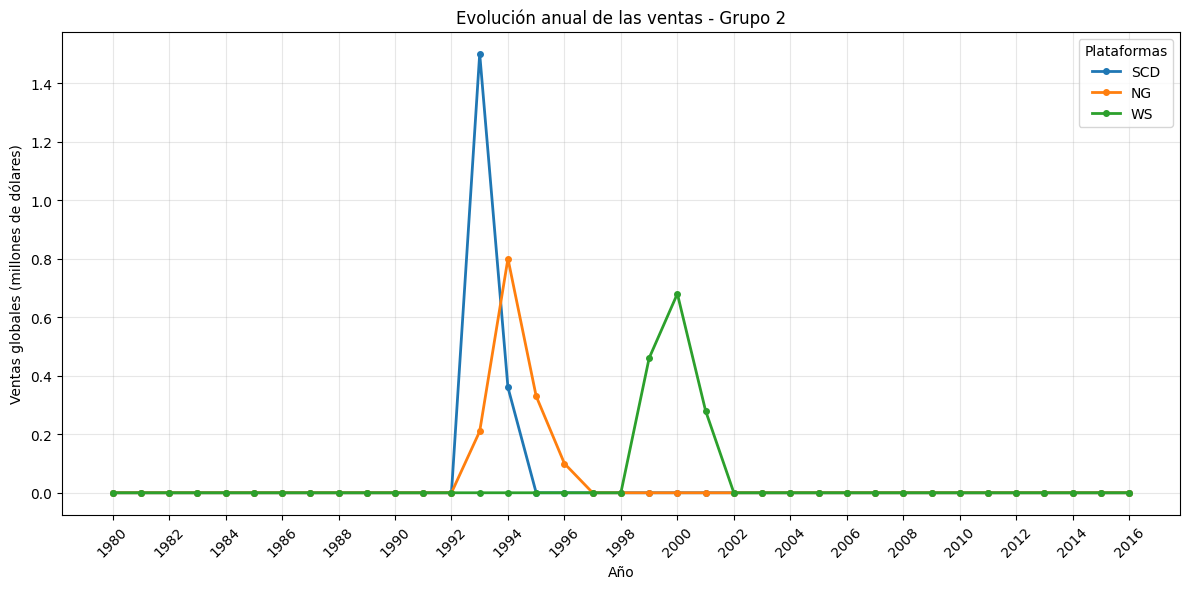

In [146]:

import matplotlib.pyplot as plt

# Identificar las plataformas del grupo 2
plataformas_grupo_2 = ventas_totales_df.index[
    ventas_totales_df['grupo'] == 2
]

# Graficar las ventas anuales
plt.figure(figsize=(12, 6))

for plataforma in plataformas_grupo_2:
    plt.plot(
        ventas_plataforma_año.index,
        ventas_plataforma_año[plataforma],
        marker='o',
        markersize=4,
        linewidth=2,
        label=plataforma
    )

plt.title('Evolución anual de las ventas - Grupo 2')
plt.xlabel('Año')
plt.ylabel('Ventas globales (millones de dólares)')
plt.xticks(range(1980, 2017, 2), rotation=45)

plt.legend(title='Plataformas')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [147]:

# Identificar las plataformas del grupo 2
plataformas_grupo_2 = ventas_totales_df.index[
    ventas_totales_df['grupo'] == 2
].tolist()

# Filtrar los datos originales del grupo 2
datos_grupo_2 = (
    df.dropna(subset=['year_of_release'])
    .loc[lambda datos: datos['platform'].isin(plataformas_grupo_2)]
    .groupby(['year_of_release', 'platform'])
    .agg(
        ventas=('total_sales', 'sum'),
        registros=('total_sales', 'size')
    )
)

# Tabla de ventas anuales: incluir todos los años de 1980 a 2016
tabla_ventas_grupo_2 = (
    datos_grupo_2['ventas']
    .unstack('platform')
    .reindex(index=range(1980, 2017), fill_value=0)
    .fillna(0)
)

# Tabla de cantidad de registros originales
tabla_registros_grupo_2 = (
    datos_grupo_2['registros']
    .unstack('platform')
    .reindex(index=range(1980, 2017), fill_value=0)
    .fillna(0)
    .astype(int)
)

print("VENTAS ANUALES - GRUPO 2")
print(tabla_ventas_grupo_2.to_string())

print("\nCANTIDAD DE REGISTROS ORIGINALES - GRUPO 2")
print(tabla_registros_grupo_2.to_string())


VENTAS ANUALES - GRUPO 2
platform           NG   SCD    WS
year_of_release                  
1980             0.00  0.00  0.00
1981             0.00  0.00  0.00
1982             0.00  0.00  0.00
1983             0.00  0.00  0.00
1984             0.00  0.00  0.00
1985             0.00  0.00  0.00
1986             0.00  0.00  0.00
1987             0.00  0.00  0.00
1988             0.00  0.00  0.00
1989             0.00  0.00  0.00
1990             0.00  0.00  0.00
1991             0.00  0.00  0.00
1992             0.00  0.00  0.00
1993             0.21  1.50  0.00
1994             0.80  0.36  0.00
1995             0.33  0.00  0.00
1996             0.10  0.00  0.00
1997             0.00  0.00  0.00
1998             0.00  0.00  0.00
1999             0.00  0.00  0.46
2000             0.00  0.00  0.68
2001             0.00  0.00  0.28
2002             0.00  0.00  0.00
2003             0.00  0.00  0.00
2004             0.00  0.00  0.00
2005             0.00  0.00  0.00
2006             0.00  

In [148]:

# Obtener las plataformas del grupo 2
plataformas_grupo_2 = ventas_totales_df.index[
    ventas_totales_df['grupo'] == 2
].tolist()

# Agrupar los registros originales por plataforma y año
ventas_reales_grupo_2 = (
    df.dropna(subset=['year_of_release'])
    .loc[lambda datos: datos['platform'].isin(plataformas_grupo_2)]
    .groupby(['platform', 'year_of_release'])
    .agg(
        ventas_anuales=('total_sales', 'sum'),
        registros=('total_sales', 'size')
    )
    .reset_index()
    .sort_values(['platform', 'year_of_release'])
)

# Mostrar únicamente los años con ventas positivas
años_con_ventas_grupo_2 = ventas_reales_grupo_2[
    ventas_reales_grupo_2['ventas_anuales'] > 0
].copy()

print("AÑOS EN LOS QUE CADA PLATAFORMA DEL GRUPO 2 REGISTRÓ VENTAS POSITIVAS")
print(años_con_ventas_grupo_2.to_string(index=False))


AÑOS EN LOS QUE CADA PLATAFORMA DEL GRUPO 2 REGISTRÓ VENTAS POSITIVAS
platform  year_of_release  ventas_anuales  registros
      NG             1993            0.21          2
      NG             1994            0.80          4
      NG             1995            0.33          4
      NG             1996            0.10          2
     SCD             1993            1.50          1
     SCD             1994            0.36          5
      WS             1999            0.46          2
      WS             2000            0.68          2
      WS             2001            0.28          2


De la misma manera que el grupo 1, en el grupo 2 tambien el total de las ventas corresponden a unos picos de ventas que se podrian comparar con modas de las diferentes plataformas, aunque se determina que con un numero mas alto de ventas totales, los años en loq ue se tienen impacto pasan de ser aproximadamente 1 a aproximadamente 3 años.

In [149]:

# Obtener las plataformas del grupo 3
plataformas_grupo_3 = ventas_totales_df.index[
    ventas_totales_df['grupo'] == 3
].tolist()

# Agrupar los registros originales por plataforma y año
ventas_reales_grupo_3 = (
    df.dropna(subset=['year_of_release'])
    .loc[lambda datos: datos['platform'].isin(plataformas_grupo_3)]
    .groupby(['platform', 'year_of_release'])
    .agg(
        ventas_anuales=('total_sales', 'sum'),
        registros=('total_sales', 'size')
    )
    .reset_index()
    .sort_values(['platform', 'year_of_release'])
)

# Mostrar únicamente los años con ventas positivas
años_con_ventas_grupo_3 = ventas_reales_grupo_3[
    ventas_reales_grupo_3['ventas_anuales'] > 0
].copy()

print("AÑOS EN LOS QUE CADA PLATAFORMA DEL GRUPO 3 REGISTRÓ VENTAS POSITIVAS")
print(años_con_ventas_grupo_3.to_string(index=False))


AÑOS EN LOS QUE CADA PLATAFORMA DEL GRUPO 3 REGISTRÓ VENTAS POSITIVAS
platform  year_of_release  ventas_anuales  registros
      DC             1998            3.38          7
      DC             1999            5.16         14
      DC             2000            5.99         20
      DC             2001            1.07          8
      DC             2002            0.29          1
      DC             2007            0.02          1
      DC             2008            0.04          1
     GEN             1990            2.60          1
     GEN             1991            4.33          1
     GEN             1992           12.64          6
     GEN             1993            3.07          9
     GEN             1994            8.13         12
     SAT             1994            3.65         19
     SAT             1995           11.57         52
     SAT             1996            7.69         38
     SAT             1997            6.77         34
     SAT             1998    

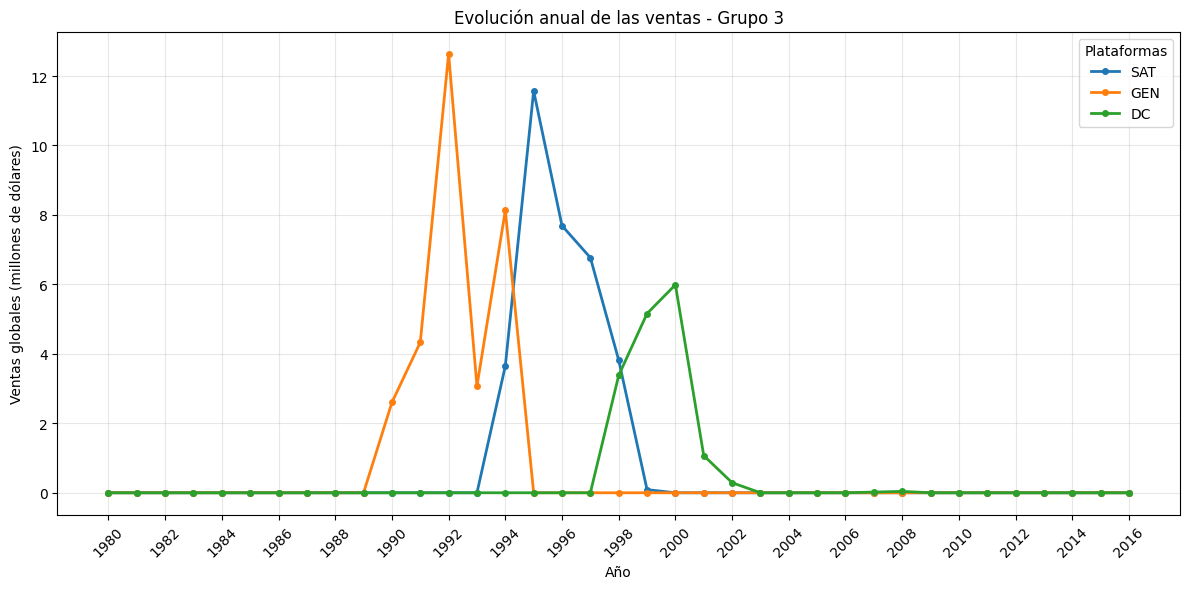

In [150]:

import matplotlib.pyplot as plt

# Obtener las plataformas del grupo 3
plataformas_grupo_3 = ventas_totales_df.index[
    ventas_totales_df['grupo'] == 3
]

# Graficar la evolución de las ventas anuales
plt.figure(figsize=(12, 6))

for plataforma in plataformas_grupo_3:
    plt.plot(
        ventas_plataforma_año.index,
        ventas_plataforma_año[plataforma],
        marker='o',
        markersize=4,
        linewidth=2,
        label=plataforma
    )

plt.title('Evolución anual de las ventas - Grupo 3')
plt.xlabel('Año')
plt.ylabel('Ventas globales (millones de dólares)')
plt.xticks(range(1980, 2017, 2), rotation=45)

plt.legend(title='Plataformas')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


para el grupo 3 de mayires ventas reportadas, se determina que la 'moda' asociada a las ventas en diferentes años aumenta, y son de aproximadamente 6 años en los que se presentan eventos y ventas. 


In [151]:

# Obtener las plataformas del grupo 4
plataformas_grupo_4 = ventas_totales_df.index[
    ventas_totales_df['grupo'] == 4
].tolist()

# Agrupar los registros originales por plataforma y año
ventas_reales_grupo_4 = (
    df.dropna(subset=['year_of_release'])
    .loc[lambda datos: datos['platform'].isin(plataformas_grupo_4)]
    .groupby(['platform', 'year_of_release'])
    .agg(
        ventas_anuales=('total_sales', 'sum'),
        registros=('total_sales', 'size')
    )
    .reset_index()
    .sort_values(['platform', 'year_of_release'])
)

# Mostrar únicamente los años con ventas positivas
años_con_ventas_grupo_4 = ventas_reales_grupo_4[
    ventas_reales_grupo_4['ventas_anuales'] > 0
].copy()

print("AÑOS CON VENTAS POSITIVAS - GRUPO 4")
print(años_con_ventas_grupo_4.to_string(index=False))


AÑOS CON VENTAS POSITIVAS - GRUPO 4
platform  year_of_release  ventas_anuales  registros
    2600             1980           11.38          9
    2600             1981           35.68         46
    2600             1982           28.88         36
    2600             1983            5.84         11
    2600             1984            0.27          1
    2600             1985            0.45          1
    2600             1986            0.67          2
    2600             1987            1.94          6
    2600             1988            0.74          2
    2600             1989            0.63          2
     PSV             2011            4.63         18
     PSV             2012           16.19         53
     PSV             2013           10.59         63
     PSV             2014           11.90        100
     PSV             2015            6.25        110
     PSV             2016            4.25         85
    WiiU             2012           17.56         32
    WiiU  

In [152]:

# Resumir ventas y cantidad de registros por año y plataforma
datos_grupo_4 = (
    df.dropna(subset=['year_of_release'])
    .loc[lambda datos: datos['platform'].isin(plataformas_grupo_4)]
    .groupby(['year_of_release', 'platform'])
    .agg(
        ventas=('total_sales', 'sum'),
        registros=('total_sales', 'size')
    )
)

# Tabla de ventas: completar los años sin registros con cero
tabla_ventas_grupo_4 = (
    datos_grupo_4['ventas']
    .unstack('platform')
    .reindex(index=range(1980, 2017), fill_value=0)
    .fillna(0)
)

# Tabla de registros originales
tabla_registros_grupo_4 = (
    datos_grupo_4['registros']
    .unstack('platform')
    .reindex(index=range(1980, 2017), fill_value=0)
    .fillna(0)
    .astype(int)
)

print("VENTAS ANUALES - GRUPO 4")
print(tabla_ventas_grupo_4.to_string())

print("\nREGISTROS ORIGINALES POR AÑO - GRUPO 4")
print(tabla_registros_grupo_4.to_string())


VENTAS ANUALES - GRUPO 4
platform          2600    PSV   WiiU
year_of_release                     
1980             11.38   0.00   0.00
1981             35.68   0.00   0.00
1982             28.88   0.00   0.00
1983              5.84   0.00   0.00
1984              0.27   0.00   0.00
1985              0.45   0.00   0.00
1986              0.67   0.00   0.00
1987              1.94   0.00   0.00
1988              0.74   0.00   0.00
1989              0.63   0.00   0.00
1990              0.00   0.00   0.00
1991              0.00   0.00   0.00
1992              0.00   0.00   0.00
1993              0.00   0.00   0.00
1994              0.00   0.00   0.00
1995              0.00   0.00   0.00
1996              0.00   0.00   0.00
1997              0.00   0.00   0.00
1998              0.00   0.00   0.00
1999              0.00   0.00   0.00
2000              0.00   0.00   0.00
2001              0.00   0.00   0.00
2002              0.00   0.00   0.00
2003              0.00   0.00   0.00
2004         

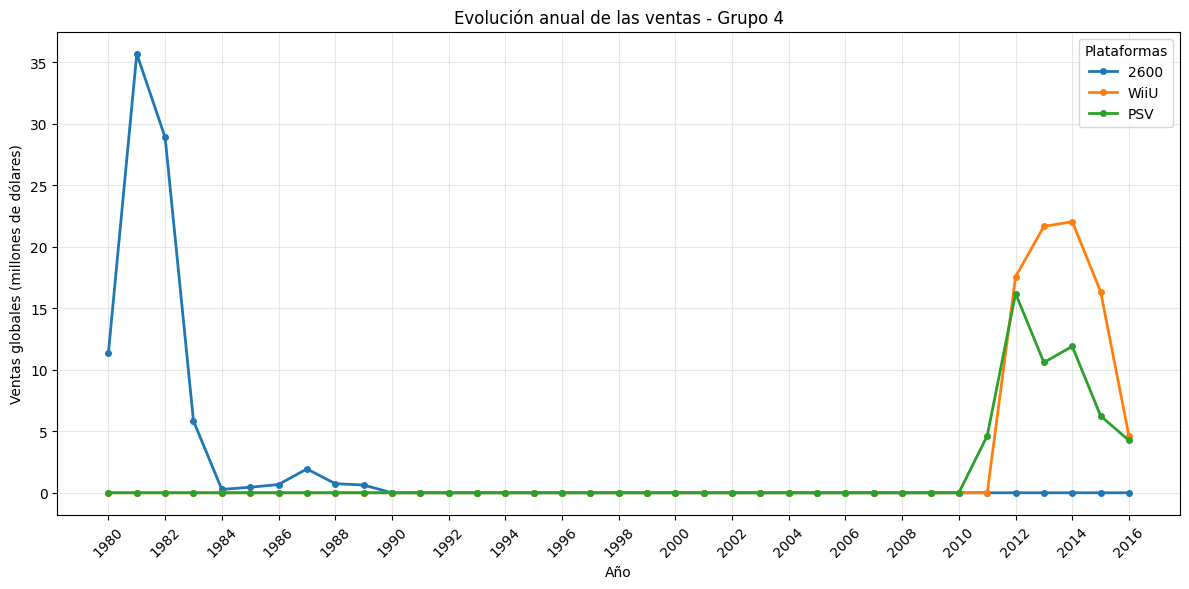

In [153]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for plataforma in plataformas_grupo_4:
    plt.plot(
        ventas_plataforma_año.index,
        ventas_plataforma_año[plataforma],
        marker='o',
        markersize=4,
        linewidth=2,
        label=plataforma
    )

plt.title('Evolución anual de las ventas - Grupo 4')
plt.xlabel('Año')
plt.ylabel('Ventas globales (millones de dólares)')
plt.xticks(range(1980, 2017, 2), rotation=45)

plt.legend(title='Plataformas')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


este grupo es interesante, porque muestra algo particular, ya que reporta ventas igualmente agrupadas en años que porian ser modas, pero demiestra que el valor de las ventas no obedece a el año de lanzamientopues la paltaforma 2600 reporto ventas elevadas y en los primeros años del estudio, lo que si se reporta enventos en 10 años consecutivos. 
se nota que al igual que en todos los casos se puestra un pico, pero la persistencia es mayor en el tiempo en estas plataformas que reportan mayores ventas

In [154]:

# Calcular ventas mínimas y máximas por grupo
resumen_grupos = (
    ventas_totales_df.groupby('grupo')['total_sales']
    .agg(
        ventas_minimas='min',
        ventas_maximas='max',
        promedio='mean',
        mediana='median',
        cantidad_plataformas='count'
    )
)

print(resumen_grupos.round(2))


       ventas_minimas  ventas_maximas  promedio  mediana  cantidad_plataformas
grupo                                                                         
1                0.03            0.16      0.08     0.07                     4
2                1.42            1.86      1.57     1.44                     3
3               15.95           33.59     26.77    30.77                     3
4               54.07           96.98     77.75    82.19                     3
5              159.32          317.85    248.81   256.60                    12
6              730.86         1255.77    935.22   923.58                     6


In [155]:


# Obtener las plataformas del grupo 5
plataformas_grupo_5 = ventas_totales_df.index[
    ventas_totales_df['grupo'] == 5
].tolist()

# Agrupar los registros originales por plataforma y año
ventas_reales_grupo_5 = (
    df.dropna(subset=['year_of_release'])
    .loc[lambda datos: datos['platform'].isin(plataformas_grupo_5)]
    .groupby(['platform', 'year_of_release'])
    .agg(
        ventas_anuales=('total_sales', 'sum'),
        registros=('total_sales', 'size')
    )
    .reset_index()
    .sort_values(['platform', 'year_of_release'])
)

# Mostrar únicamente los años con ventas positivas
años_con_ventas_grupo_5 = ventas_reales_grupo_5[
    ventas_reales_grupo_5['ventas_anuales'] > 0
].copy()

print("AÑOS CON VENTAS POSITIVAS - GRUPO 5")
print(años_con_ventas_grupo_5.to_string(index=False))


AÑOS CON VENTAS POSITIVAS - GRUPO 5
platform  year_of_release  ventas_anuales  registros
     3DS             2011           63.20        116
     3DS             2012           51.36         93
     3DS             2013           56.57         91
     3DS             2014           43.76         80
     3DS             2015           27.78         86
     3DS             2016           15.14         46
      GB             1988            1.43          1
      GB             1989           64.97         10
      GB             1990            4.89          3
      GB             1991            5.57          9
      GB             1992           25.49          7
      GB             1994           12.18          3
      GB             1995            3.60          4
      GB             1996           36.03          6
      GB             1997            6.37          8
      GB             1998           26.90          8
      GB             1999           38.00         11
      GB  

In [156]:

# Resumir ventas y registros originales por año y plataforma
datos_grupo_5 = (
    df.dropna(subset=['year_of_release'])
    .loc[lambda datos: datos['platform'].isin(plataformas_grupo_5)]
    .groupby(['year_of_release', 'platform'])
    .agg(
        ventas=('total_sales', 'sum'),
        registros=('total_sales', 'size')
    )
)

# Tabla de ventas anuales
tabla_ventas_grupo_5 = (
    datos_grupo_5['ventas']
    .unstack('platform')
    .reindex(index=range(1980, 2017), fill_value=0)
    .fillna(0)
)

# Tabla de cantidad de registros originales
tabla_registros_grupo_5 = (
    datos_grupo_5['registros']
    .unstack('platform')
    .reindex(index=range(1980, 2017), fill_value=0)
    .fillna(0)
    .astype(int)
)

print("VENTAS ANUALES - GRUPO 5")
print(tabla_ventas_grupo_5.to_string())

print("\nREGISTROS ORIGINALES POR AÑO - GRUPO 5")
print(tabla_registros_grupo_5.to_string())


VENTAS ANUALES - GRUPO 5
platform           3DS     GB    GBA     GC    N64    NES     PC     PS4    PSP   SNES     XB   XOne
year_of_release                                                                                     
1980              0.00   0.00   0.00   0.00   0.00   0.00   0.00    0.00   0.00   0.00   0.00   0.00
1981              0.00   0.00   0.00   0.00   0.00   0.00   0.00    0.00   0.00   0.00   0.00   0.00
1982              0.00   0.00   0.00   0.00   0.00   0.00   0.00    0.00   0.00   0.00   0.00   0.00
1983              0.00   0.00   0.00   0.00   0.00  10.96   0.00    0.00   0.00   0.00   0.00   0.00
1984              0.00   0.00   0.00   0.00   0.00  50.08   0.00    0.00   0.00   0.00   0.00   0.00
1985              0.00   0.00   0.00   0.00   0.00  53.44   0.04    0.00   0.00   0.00   0.00   0.00
1986              0.00   0.00   0.00   0.00   0.00  36.41   0.00    0.00   0.00   0.00   0.00   0.00
1987              0.00   0.00   0.00   0.00   0.00  19.76   0.00  

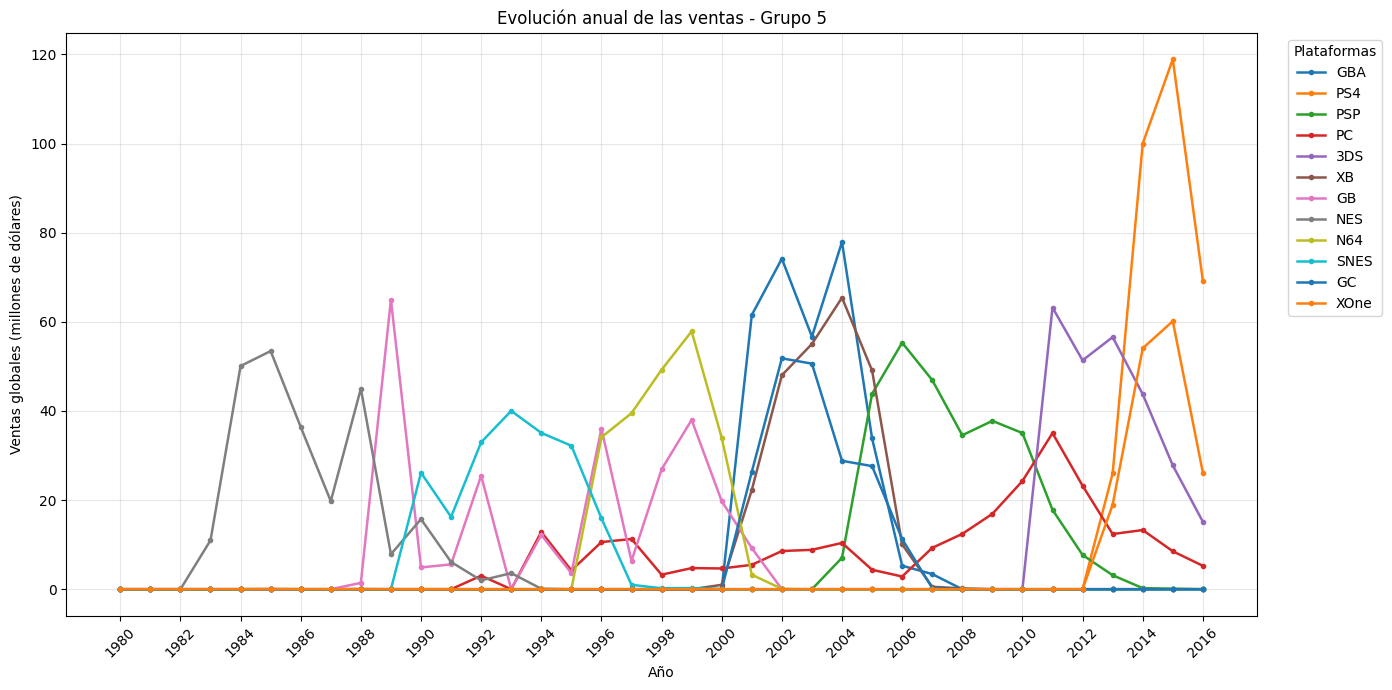

In [157]:

import matplotlib.pyplot as plt

# Obtener las plataformas del grupo 5
plataformas_grupo_5 = ventas_totales_df.index[
    ventas_totales_df['grupo'] == 5
]

# Graficar las ventas anuales
plt.figure(figsize=(14, 7))

for plataforma in plataformas_grupo_5:
    plt.plot(
        ventas_plataforma_año.index,
        ventas_plataforma_año[plataforma],
        marker='o',
        markersize=3,
        linewidth=1.8,
        label=plataforma
    )

plt.title('Evolución anual de las ventas - Grupo 5')
plt.xlabel('Año')
plt.ylabel('Ventas globales (millones de dólares)')
plt.xticks(range(1980, 2017, 2), rotation=45)

plt.legend(
    title='Plataformas',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


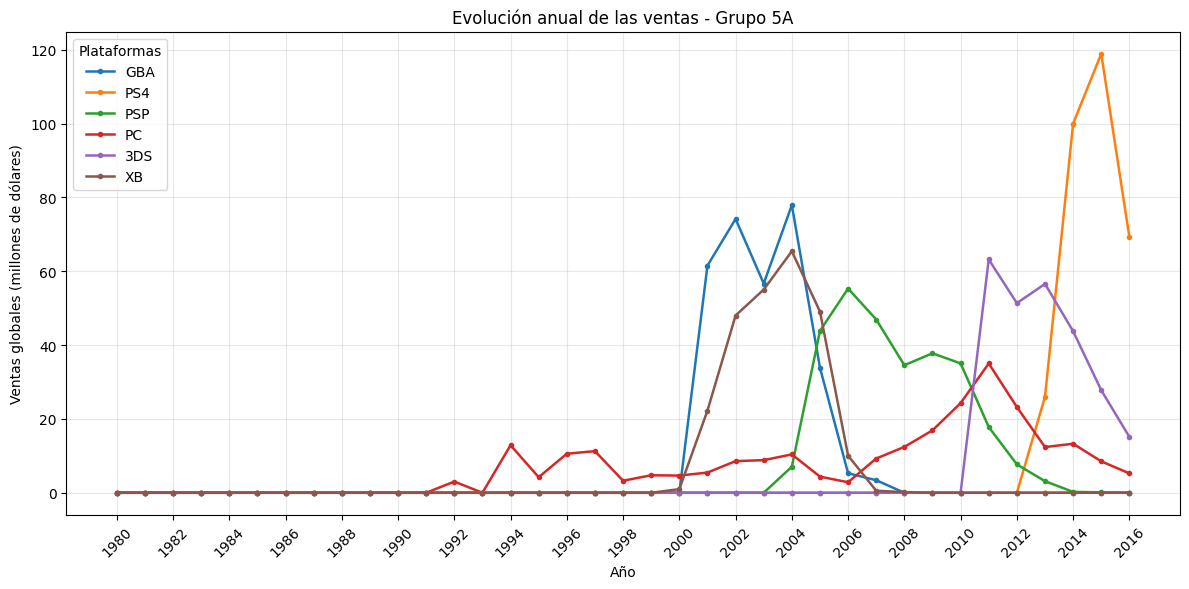

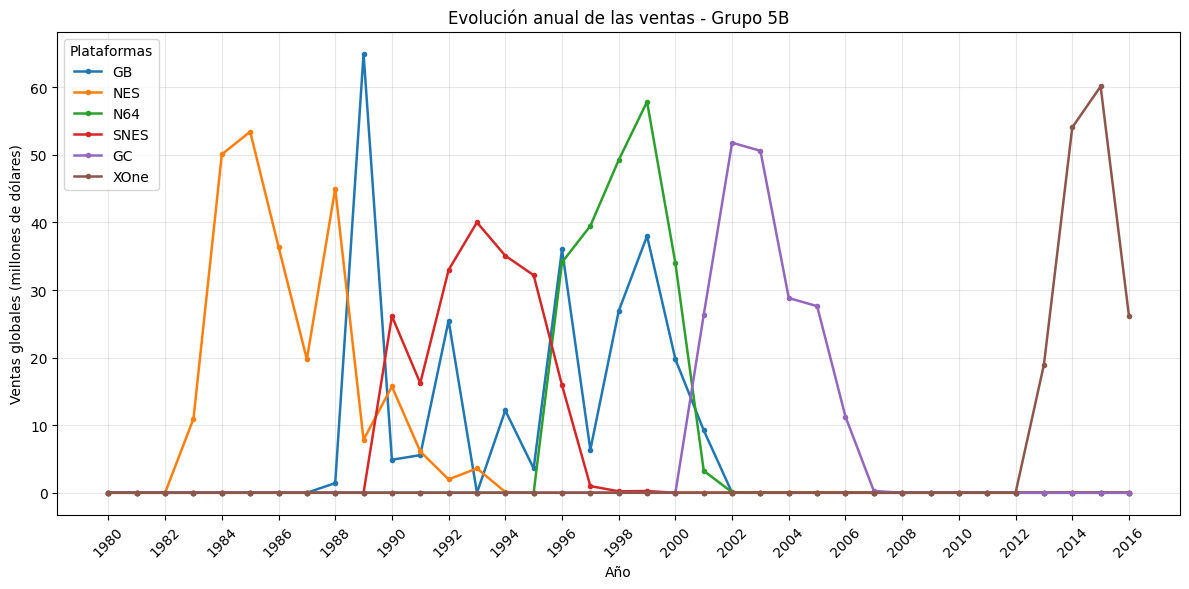

In [158]:

import matplotlib.pyplot as plt

plataformas_grupo_5 = ventas_totales_df.index[
    ventas_totales_df['grupo'] == 5
].tolist()

# Ordenar las plataformas por sus ventas totales
plataformas_grupo_5 = (
    ventas_totales_df.loc[plataformas_grupo_5]
    .sort_values('total_sales', ascending=False)
    .index.tolist()
)

# Dividir las plataformas en dos grupos de seis
subgrupo_5a = plataformas_grupo_5[:6]
subgrupo_5b = plataformas_grupo_5[6:]

for nombre_subgrupo, plataformas in [
    ('5A', subgrupo_5a),
    ('5B', subgrupo_5b)
]:
    plt.figure(figsize=(12, 6))

    for plataforma in plataformas:
        plt.plot(
            ventas_plataforma_año.index,
            ventas_plataforma_año[plataforma],
            marker='o',
            markersize=3,
            linewidth=1.8,
            label=plataforma
        )

    plt.title(
        f'Evolución anual de las ventas - Grupo 5{nombre_subgrupo[-1]}'
    )
    plt.xlabel('Año')
    plt.ylabel('Ventas globales (millones de dólares)')
    plt.xticks(range(1980, 2017, 2), rotation=45)
    plt.legend(title='Plataformas')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


para el analisis de estre grupo, se identifican las plataformas que reportan mayores ventas que los grupos anteriores, y en este caso el comportamoewnto de las ventas tambien es un tanto diferentes. se ven comportamientos mucho mas distribuidos en el tiempo y con episodios en varios años. lo que indica que el impacto de estos juegos en la poblacion no solo fueron unos pocos años, sino que se ha venido actializando su favoritismo a lo mejor debido a una actualizacion de su contenido. estas son platafiormas que no pierden vigencia rapidamente y que generan impacto. casos como la plataforma'NES' que domino el mercado en los años82 y que logro tener reportes en ventas hasta el año 93, casi 11 años reportando ventas. para el analisis de este grupo propuesto de 12 plataformas desidi dividir en 2 tablas para evitar que las lineas se solapen. 

In [159]:

# Identificar las plataformas del grupo 6
plataformas_grupo_6 = ventas_totales_df.index[
    ventas_totales_df['grupo'] == 6
].tolist()

# Calcular las ventas por plataforma y año
ventas_reales_grupo_6 = (
    df.dropna(subset=['year_of_release'])
    .loc[lambda datos: datos['platform'].isin(plataformas_grupo_6)]
    .groupby(['platform', 'year_of_release'])
    .agg(
        ventas_anuales=('total_sales', 'sum'),
        registros=('total_sales', 'size')
    )
    .reset_index()
    .sort_values(['platform', 'year_of_release'])
)

# Crear tabla con todos los años disponibles
tabla_ventas_grupo_6 = (
    ventas_plataforma_año[plataformas_grupo_6]
    .reindex(range(1980, 2017), fill_value=0)
)

display(tabla_ventas_grupo_6.round(2))


platform,PS2,X360,PS3,Wii,DS,PS
year_of_release,,,,,,
1980,0.00,0.00,0.00,0.00,0.00,0.00
1981,0.00,0.00,0.00,0.00,0.00,0.00
1982,0.00,0.00,0.00,0.00,0.00,0.00
1983,0.00,0.00,0.00,0.00,0.00,0.00
1984,0.00,0.00,0.00,0.00,0.00,0.00
1985,0.00,0.00,0.00,0.00,0.02,0.00
1986,0.00,0.00,0.00,0.00,0.00,0.00
1987,0.00,0.00,0.00,0.00,0.00,0.00
1988,0.00,0.00,0.00,0.00,0.00,0.00


In [160]:

tabla_registros_grupo_6 = (
    df.dropna(subset=['year_of_release'])
    .loc[lambda datos: datos['platform'].isin(plataformas_grupo_6)]
    .pivot_table(
        index='year_of_release',
        columns='platform',
        values='total_sales',
        aggfunc='size',
        fill_value=0
    )
    .reindex(range(1980, 2017), fill_value=0)
)

display(tabla_registros_grupo_6)


platform,DS,PS,PS2,PS3,Wii,X360
year_of_release,,,,,,
1980,0,0,0,0,0,0
1981,0,0,0,0,0,0
1982,0,0,0,0,0,0
1983,0,0,0,0,0,0
1984,0,0,0,0,0,0
1985,1,0,0,0,0,0
1986,0,0,0,0,0,0
1987,0,0,0,0,0,0
1988,0,0,0,0,0,0


In [161]:

años_con_ventas_grupo_6 = ventas_reales_grupo_6[
    ventas_reales_grupo_6['ventas_anuales'] > 0
].copy()

display(años_con_ventas_grupo_6)


,platform,year_of_release,ventas_anuales,registros
0,DS,1985,0.02,1
1,DS,2004,17.27,23
2,DS,2005,130.14,118
3,DS,2006,119.81,201
4,DS,2007,146.94,376
...,...,...,...,...
62,X360,2012,99.74,106
63,X360,2013,88.58,75
64,X360,2014,34.74,63
65,X360,2015,11.96,35


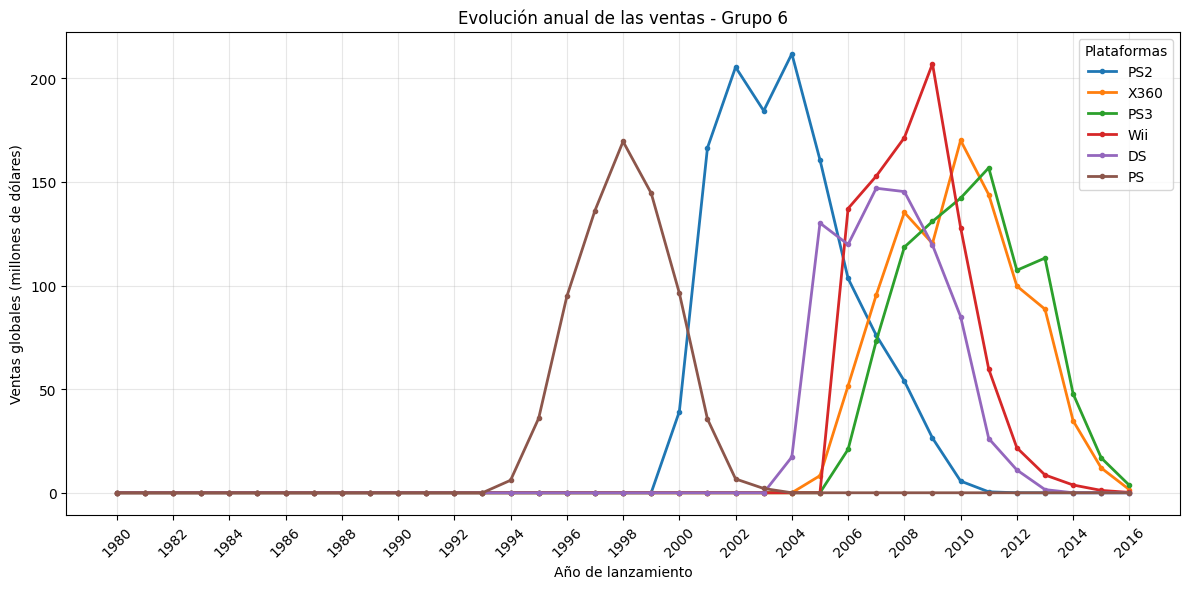

In [162]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for plataforma in plataformas_grupo_6:
    plt.plot(
        ventas_plataforma_año.index,
        ventas_plataforma_año[plataforma],
        marker='o',
        markersize=3,
        linewidth=2,
        label=plataforma
    )

plt.title('Evolución anual de las ventas - Grupo 6')
plt.xlabel('Año de lanzamiento')
plt.ylabel('Ventas globales (millones de dólares)')
plt.xticks(range(1980, 2017, 2), rotation=45)
plt.legend(title='Plataformas')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


igual que en los anteriores grupos muestra unos picos en las ventas de diferentes videojuegos, pero que no perduran en el tiempo a mas de 10 años.
    parece ser que es un buen promotor de mercado el innovar con nuevas plataformas. 

In [163]:

import pandas as pd

# Contar en cuántos años diferentes cada plataforma reportó ventas positivas
años_con_ventas_positivas = (
    df.dropna(subset=['year_of_release'])
    .loc[df['total_sales'] > 0]
    .groupby('platform')['year_of_release']
    .nunique()
    .rename('años_con_ventas')
)

# Contar los registros de juegos que reportaron ventas positivas
registros_con_ventas = (
    df.loc[df['total_sales'] > 0]
    .groupby('platform')
    .size()
    .rename('registros_con_ventas')
)

# Calcular las ventas acumuladas por plataforma
ventas_acumuladas = (
    df.groupby('platform')['total_sales']
    .sum()
    .rename('ventas_totales')
)

# Unir los resultados y agregar el grupo de K-means
tabla_plataformas = pd.concat(
    [
        años_con_ventas_positivas,
        registros_con_ventas,
        ventas_acumuladas
    ],
    axis=1
).reset_index()

tabla_plataformas = tabla_plataformas.merge(
    ventas_totales_df[['grupo']],
    left_on='platform',
    right_index=True,
    how='left'
)

# Ordenar por cantidad de años con ventas y mostrar primero las más persistentes
tabla_plataformas = tabla_plataformas.sort_values(
    ['años_con_ventas', 'ventas_totales'],
    ascending=[False, False]
).reset_index(drop=True)

display(tabla_plataformas.round(2))


,platform,años_con_ventas,registros_con_ventas,ventas_totales,grupo
0,PC,26,974,259.52,5
1,GB,13,98,255.46,5
2,PS2,12,2160,1255.77,6
3,X360,12,1262,971.42,6
4,PSP,12,1209,294.05,5
5,NES,12,98,251.05,5
6,PS3,11,1330,939.65,6
7,Wii,11,1320,907.51,6
8,DS,11,2151,806.12,6
9,PS,10,1197,730.86,6


en la tabla anterior nos muestra el numero de años en los que la plataforma reporta ventas, para determinar que tanto impactan en el mercado y el grupo al que pertenecen, ya que la eficiencia o no radica en el valor total de las ventas. es importante porque podria determinar plataformas con excelente aceptacion por el publico pero que no logro mantenerce en el tiempo. como dato adicional se reporta que no hay ninguna plataforma que logre reinventarce y que logra reportar ventas en tiempos diferentes. osea no se logra dominar en los 80 y en los 2000. podria ser un excelente dato si lo que se quiere es tratar de impulsar una plataforma, segun los datos es mejor la creacion de una nueva, una vez la anterior pierde vigencia. claro que estos datos deben ser analizados de manera mas extenza y mirar posibles causas. seria interesante para un analisis más profundo determinar cual de las regiones impulsa mas las ventas y en que nicho deberia prestarce mayor atencion. 

In [164]:

# Filtrar los datos del período reciente
datos_periodo_reciente = df[
    df['year_of_release'].between(2008, 2016)
].copy()

# Ventas globales por plataforma y año
ventas_recientes = (
    datos_periodo_reciente
    .pivot_table(
        index='year_of_release',
        columns='platform',
        values='total_sales',
        aggfunc='sum',
        fill_value=0
    )
    .sort_index()
)

display(ventas_recientes.round(2))


platform,3DS,DC,DS,PC,PS2,PS3,PS4,PSP,PSV,Wii,WiiU,X360,XB,XOne
year_of_release,,,,,,,,,,,,,,
2008,0.00,0.04,145.31,12.42,53.90,118.52,0.00,34.55,0.00,171.32,0.00,135.26,0.18,0.00
2009,0.00,0.00,119.54,16.91,26.40,130.93,0.00,37.78,0.00,206.97,0.00,120.29,0.00,0.00
2010,0.00,0.00,85.02,24.28,5.64,142.17,0.00,35.04,0.00,127.95,0.00,170.03,0.00,0.00
2011,63.20,0.00,26.18,35.03,0.45,156.78,0.00,17.82,4.63,59.65,0.00,143.84,0.00,0.00
2012,51.36,0.00,11.01,23.22,0.00,107.36,0.00,7.69,16.19,21.71,17.56,99.74,0.00,0.00
2013,56.57,0.00,1.54,12.38,0.00,113.25,25.99,3.14,10.59,8.59,21.65,88.58,0.00,18.96
2014,43.76,0.00,0.00,13.28,0.00,47.76,100.00,0.24,11.90,3.75,22.03,34.74,0.00,54.07
2015,27.78,0.00,0.00,8.52,0.00,16.82,118.90,0.12,6.25,1.14,16.35,11.96,0.00,60.14
2016,15.14,0.00,0.00,5.25,0.00,3.60,69.25,0.00,4.25,0.18,4.60,1.52,0.00,26.15


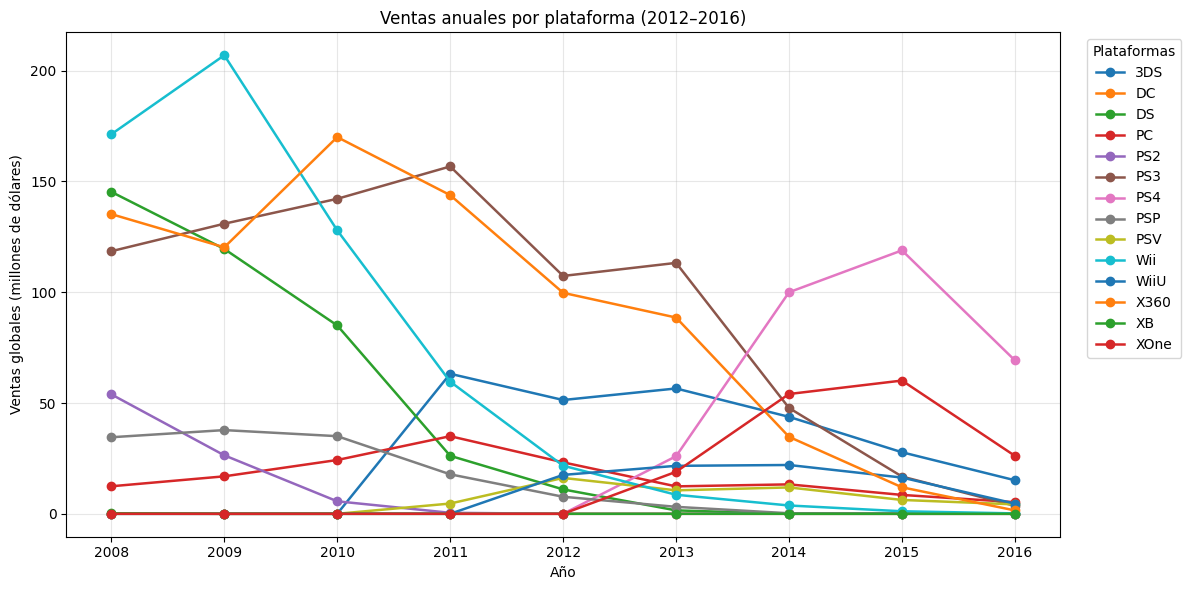

In [165]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for plataforma in ventas_recientes.columns:
    plt.plot(
        ventas_recientes.index,
        ventas_recientes[plataforma],
        marker='o',
        linewidth=1.8,
        label=plataforma
    )

plt.title('Ventas anuales por plataforma (2012–2016)')
plt.xlabel('Año')
plt.ylabel('Ventas globales (millones de dólares)')
plt.xticks(range(2008, 2017))
plt.legend(
    title='Plataformas',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


year_of_release
2008    1427
2009    1426
2010    1255
2011    1136
2012     653
2013     544
2014     581
2015     606
2016     502
Name: name, dtype: int64

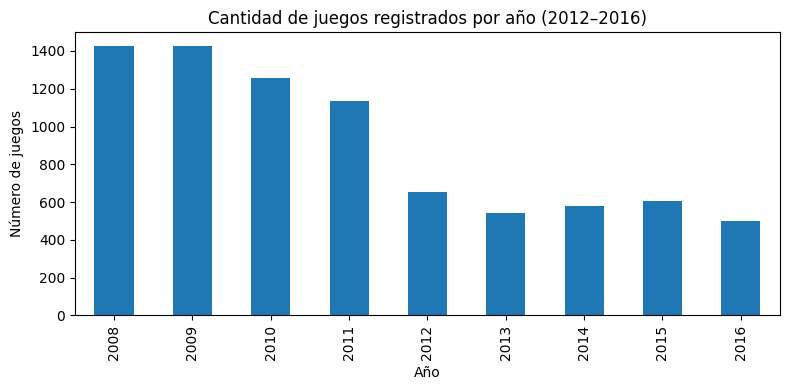

In [166]:

juegos_por_año = (
    df.dropna(subset=['year_of_release'])
    .groupby('year_of_release')['name']
    .count()
    .sort_index()
)

display(juegos_por_año.loc[2008:2016])

juegos_por_año.loc[2008:2016].plot(
    kind='bar',
    figsize=(8, 4),
    title='Cantidad de juegos registrados por año (2012–2016)',
    xlabel='Año',
    ylabel='Número de juegos',
    grid=False
)

plt.tight_layout()
plt.show()


Determina para qué período debes tomar datos. Para hacerlo mira tus respuestas a las preguntas anteriores.
en este caso teniendo en cuenta el numero de años que los mejores juegos demuestran ventas, pienso que trabajar con el año final (2016) menos 8 años (2008) podria ser un buen margen de tiempo, en este tiempo podria diferenciar de cuales son lasa plataformas que estan en crecimineto, cuales estan consolidadas y cuales estan perdiendo vigencia dentro del grupo total de plataformas. 

para este caso los datos relevantes son de las plataformas que estan aun vigentes.
¿Qué plataformas son líderes en ventas?
las plataformas lideres en ventas son 
0	PC	26	974	259.52	5
1	GB	13	98	255.46	5
2	PS2	12	2160	1255.77	6
3	X360	12	1262	971.42	6
4	PSP	12	1209	294.05	5
5	NES	12	98	251.05	5
6	PS3	11	1330	939.65	6
7	Wii	11	1320	907.51	6
8	DS	11	2151	806.12	6
9	PS	10	1197	730.86	6
pero las actuales que tienen un mejor presente son PS4 y XOne que aunque muestran una disminucion en sus ventas, aun repuntan y el tiempo de permanencia en el mercado aun augura para ellas otros años mas de ventas reportasdas, aunque la caida de las ventas del año 2015 y 2016, podria demostrar un tiempo dificil para las plataformas. se quiere con el anterior codigo determinar si para el año 2016 hay una falta de reportes pues no se tiene certeza del mes de corte de la informacion ni los lanzamientos de fin de años (si estan o no incluidos)


¿Cuáles crecen y cuáles se reducen? Elige varias plataformas potencialmente rentables.

segun lo vosto en los reportes ninguna plataforma crece entre el año 2015 y 2016, pero se podrian agrupar en las siguientes. 
. PS3 Y X360 : disminuyen fuertemente y muestran lo que podria ser su final del ciclo. 
. PS4 Y XOne : suben significativamente entre 2013 y 2015 (26 a 119 y 18.96 a 60.14 respectivamente) y juntas caen para 2016, aunque siguen siendo las de mejor comportamiento para el año de corte. 
. 3DS, PC, WiiU y PSV: muestran disminucion en ventas para los ultimos años y caidas casi totales para 2016.

In [167]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   name                16713 non-null  object 
 1   platform            16715 non-null  object 
 2   year_of_release     16446 non-null  Int64  
 3   genre               16713 non-null  object 
 4   na_sales            16715 non-null  float64
 5   eu_sales            16715 non-null  float64
 6   jp_sales            16715 non-null  float64
 7   other_sales         16715 non-null  float64
 8   critic_score        8137 non-null   float64
 9   user_score          10014 non-null  object 
 10  rating              9949 non-null   object 
 11  user_score_sin_tbd  7590 non-null   float64
 12  rating_grupo        16715 non-null  object 
 13  total_sales         16715 non-null  float64
dtypes: Int64(1), float64(7), object(6)
memory usage: 1.8+ MB


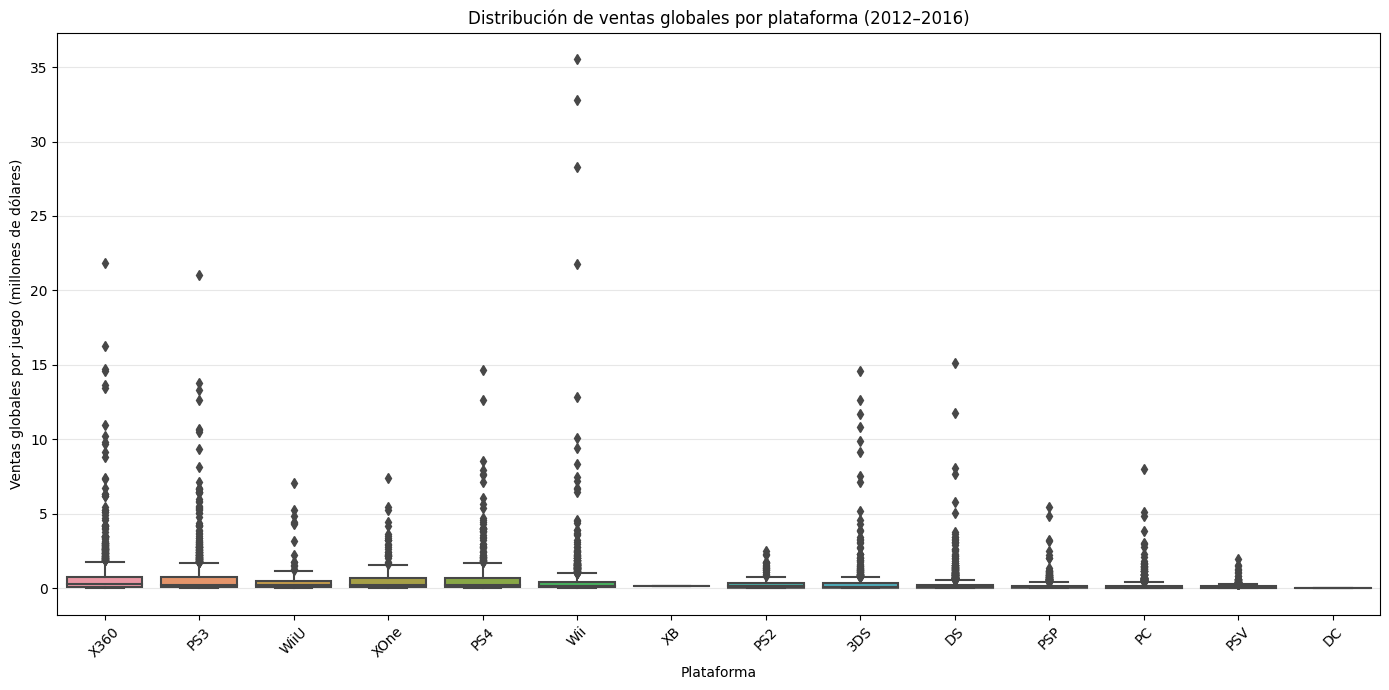

In [168]:

import matplotlib.pyplot as plt
import seaborn as sns

# Seleccionar el período de análisis
datos_ventas_caja = df[
    df['year_of_release'].between(2008, 2016)
].dropna(subset=['platform', 'total_sales']).copy()

# Ordenar las plataformas por mediana de ventas
orden_plataformas = (
    datos_ventas_caja.groupby('platform')['total_sales']
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(14, 7))

sns.boxplot(
    data=datos_ventas_caja,
    x='platform',
    y='total_sales',
    order=orden_plataformas
)

plt.title('Distribución de ventas globales por plataforma (2012–2016)')
plt.xlabel('Plataforma')
plt.ylabel('Ventas globales por juego (millones de dólares)')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


In [169]:


# Filtrar los registros desde 2008 hasta 2016
datos_juegos_recientes = df[
    df['year_of_release'].between(2008, 2016)
].dropna(subset=['platform', 'name']).copy()

# Contar los juegos por plataforma y año
tabla_juegos_plataforma_año = (
    datos_juegos_recientes
    .pivot_table(
        index='platform',
        columns='year_of_release',
        values='name',
        aggfunc='count',
        fill_value=0
    )
    .reindex(columns=range(2008, 2017), fill_value=0)
)

# Agregar el total de juegos por plataforma en el período
tabla_juegos_plataforma_año['total_2008_2016'] = (
    tabla_juegos_plataforma_año.sum(axis=1)
)

# Ordenar por el total de juegos, de mayor a menor
tabla_juegos_plataforma_año = (
    tabla_juegos_plataforma_año
    .sort_values('total_2008_2016', ascending=False)
)

display(tabla_juegos_plataforma_año)


year_of_release,2008,2009,2010,2011,2012,2013,2014,2015,2016,total_2008_2016
platform,,,,,,,,,,
DS,492,403,323,153,23,8,0,0,0,1402
PS3,138,162,181,215,148,126,108,73,38,1189
Wii,282,325,253,143,31,12,6,4,1,1057
X360,146,172,182,206,106,75,63,35,13,998
PSP,100,161,188,139,106,54,10,3,0,761
PC,76,107,90,139,61,38,47,50,54,662
3DS,0,0,0,116,93,91,80,86,46,512
PSV,0,0,0,18,53,63,100,110,85,429
PS4,0,0,0,0,0,16,75,137,164,392


segun el diagrama de cajas, se reporta una concentracion en titulos de bajas ventas, y solo unos pocos juegos reportan ventas altas. con el animo de comprender mejor las dinamircas del negocio de las plataformas, se implemento el anterior codigo determinando que del total de los juegos que lanzan las diferentes plataformas, solo las plataformas con la mejor actualidad, esta en aumentoo el numero de juegosy no reportaron para el año 2012 lanzamientos, mientras que los demás reportan dismunucion o estancamiento en los lanzamientos. 

In [170]:

from scipy.stats import kruskal

grupos_ventas = [
    grupo['total_sales'].dropna().values
    for plataforma, grupo in datos_ventas_caja.groupby('platform')
    if len(grupo['total_sales'].dropna()) > 0
]

estadistico, valor_p = kruskal(*grupos_ventas)

print(f'Estadístico H: {estadistico:.4f}')
print(f'Valor p: {valor_p:.10f}')

if valor_p < 0.05:
    print(
        'Conclusión: hay diferencias estadísticamente significativas '
        'entre las ventas de al menos algunas plataformas.'
    )
else:
    print(
        'Conclusión: no hay evidencia estadística suficiente '
        'para afirmar que las distribuciones de ventas difieren.'
    )


Estadístico H: 1019.9321
Valor p: 0.0000000000
Conclusión: hay diferencias estadísticamente significativas entre las ventas de al menos algunas plataformas.


In [171]:
ventas_plataforma = (
    df.groupby('platform')['total_sales']
    .agg(['count', 'mean', 'median', 'std'])
    .sort_values('mean', ascending=False)
)

display(ventas_plataforma)

,count,mean,median,std
platform,,,,
GB,98,2.606735,1.165,5.365478
NES,98,2.561735,1.375,5.108012
GEN,29,1.061034,0.150,1.470645
SNES,239,0.836987,0.320,1.869469
PS4,392,0.801378,0.200,1.609456
X360,1262,0.769746,0.280,1.615674
2600,133,0.729173,0.460,0.917799
PS3,1331,0.705973,0.270,1.391749
Wii,1320,0.687508,0.190,3.126609


Como el valor p es inferior a 0,05, rechazamos la hipótesis nula. Por tanto, existe evidencia estadística de que las distribuciones de ventas globales por juego difieren entre al menos algunas plataformas. usando la prueba de Kruskal_Wallis.
aunque despues de identificar que hay diferencias estadisticamente significativas, no se puede determinar con esta prueba cuales son las que difieren entre si, para eso hay que hacer pruebas con mayor detalle.
igualemnte se determina segun el diagrama de cajas que las ventas de los videojuegos en las diferentes plataformas, analizadas las de importancia desde 2012 en adelante, que cada plataforma cuenta con juegos top que venden mucho mas que el promedio, de un numero elevado de juegos que venden un valor bajo en las plataformas cercanos a 0 millones de dollares y algunos pocos muy superiores. en el diagrama de cajas se muestra una asimetria a la derecha. 

para mirar la influencia o no de las reseñas con las ventads de las diferentes plataformas se podria trabajar con una plataforma actual commo PS4, con el animo de implementar una relacion, pero teniendo en cuenta que es una plataforma que no ha pasado por todos los excenarios posibles y que es reciente, prefiero trabajar con juegos con 'ciclo completo' de lanzamiento, popularidad y desaparicion, y que adicional tenga datos reportados posteriores a 2000 que fue la fecha en la que los nan en las reseñas eran inferiores, porque el PS2 que mostro excelentes ventas, reportó su salida para 1998 en la que la realizacion de reseñas era inferior.

In [172]:

# Seleccionar todos los juegos de Wii
datos_wii = df[df['platform'] == 'Wii'].copy()

print('Total de registros de Wii:', len(datos_wii))
print('Primer año registrado:', datos_wii['year_of_release'].min())
print('Último año registrado:', datos_wii['year_of_release'].max())

print('\nDatos disponibles para el análisis:')
display(
    datos_wii[
        ['total_sales', 'critic_score', 'user_score_sin_tbd']
    ].notna().sum().rename('registros_disponibles')
)

print('\nValores faltantes:')
display(
    datos_wii[
        ['total_sales', 'critic_score', 'user_score_sin_tbd']
    ].isna().sum().rename('valores_faltantes')
)


Total de registros de Wii: 1320
Primer año registrado: 2006
Último año registrado: 2016

Datos disponibles para el análisis:


total_sales           1320
critic_score           585
user_score_sin_tbd     560
Name: registros_disponibles, dtype: int64


Valores faltantes:


total_sales             0
critic_score          735
user_score_sin_tbd    760
Name: valores_faltantes, dtype: int64

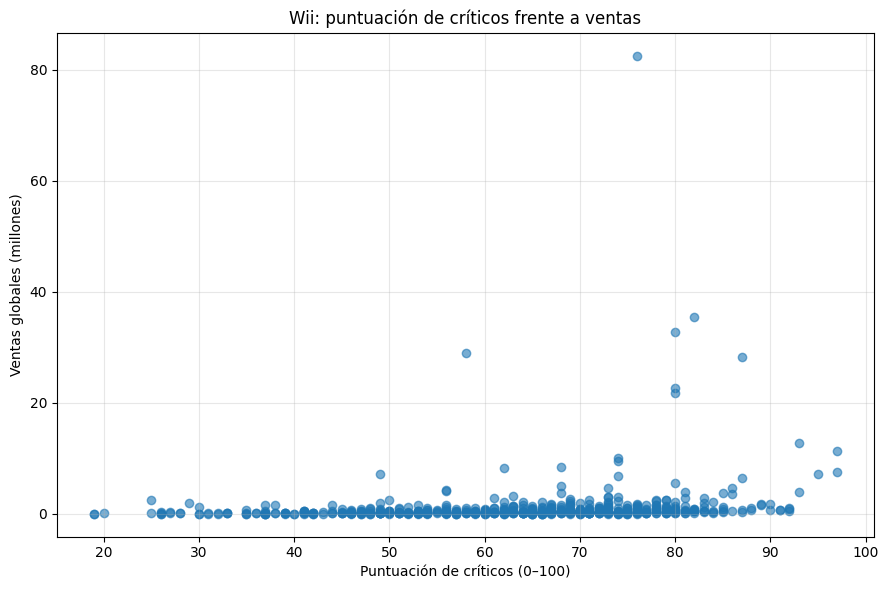

In [173]:

import matplotlib.pyplot as plt

datos_criticos_wii = datos_wii.dropna(
    subset=['critic_score', 'total_sales']
)

plt.figure(figsize=(9, 6))
plt.scatter(
    datos_criticos_wii['critic_score'],
    datos_criticos_wii['total_sales'],
    alpha=0.6
)

plt.title('Wii: puntuación de críticos frente a ventas')
plt.xlabel('Puntuación de críticos (0–100)')
plt.ylabel('Ventas globales (millones)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [174]:

correlacion_criticos_wii = datos_criticos_wii[
    ['critic_score', 'total_sales']
].corr(method='pearson').iloc[0, 1]

print(
    'Correlación entre críticos y ventas en Wii:',
    round(correlacion_criticos_wii, 3)
)


Correlación entre críticos y ventas en Wii: 0.178


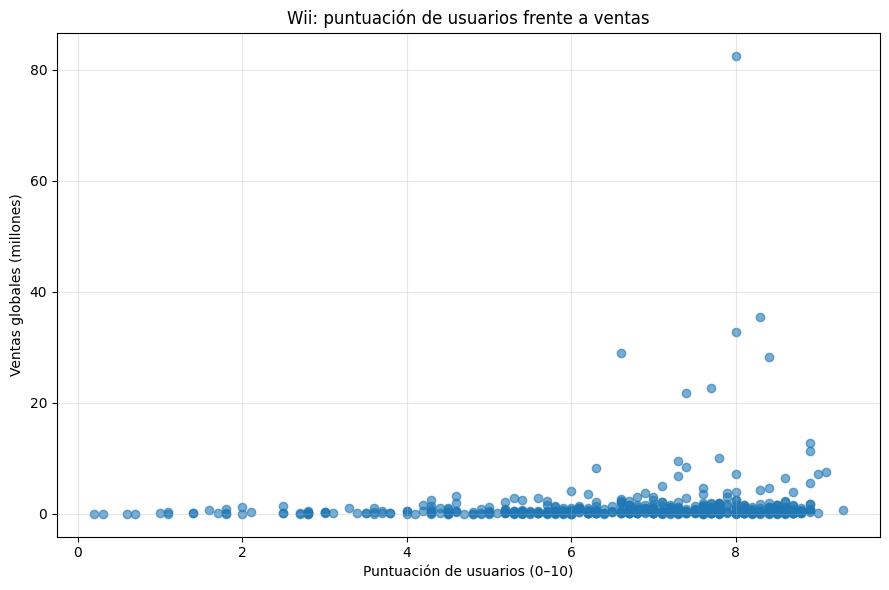

In [175]:

datos_usuarios_wii = datos_wii.dropna(
    subset=['user_score_sin_tbd', 'total_sales']
)

plt.figure(figsize=(9, 6))
plt.scatter(
    datos_usuarios_wii['user_score_sin_tbd'],
    datos_usuarios_wii['total_sales'],
    alpha=0.6
)

plt.title('Wii: puntuación de usuarios frente a ventas')
plt.xlabel('Puntuación de usuarios (0–10)')
plt.ylabel('Ventas globales (millones)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [176]:

correlacion_usuarios_wii = datos_usuarios_wii[
    ['user_score_sin_tbd', 'total_sales']
].corr(method='pearson').iloc[0, 1]

print(
    'Correlación entre usuarios y ventas en Wii:',
    round(correlacion_usuarios_wii, 3)
)


Correlación entre usuarios y ventas en Wii: 0.112


esta informacion muestra una debil correlacion positiva, y la grafica muestra unas ventas bajas y de muy buenas puntiuaciones. y solo en algunois casos son las ventas buenas con obuenas puntuaciones que son los datos mas dispersos, pero sin coinsidir las buenas puntuaciones con las mejores ventas. quiero probar con la plataforma PS2, a ver como sale, porque analisando los datos de Wii me dic eunta que aun hay muchos datos faltantes.

In [177]:

# Seleccionar todos los juegos de PS2
datos_ps2 = df[df['platform'] == 'PS2'].copy()

print('Total de registros de PS2:', len(datos_ps2))
print(
    'Primer año registrado:',
    datos_ps2['year_of_release'].min()
)
print(
    'Último año registrado:',
    datos_ps2['year_of_release'].max()
)

print('\nRegistros disponibles por variable:')
display(
    datos_ps2[
        ['total_sales', 'critic_score', 'user_score_sin_tbd']
    ].notna().sum().rename('registros_disponibles')
)


Total de registros de PS2: 2161
Primer año registrado: 2000
Último año registrado: 2011

Registros disponibles por variable:


total_sales           2161
critic_score          1298
user_score_sin_tbd    1241
Name: registros_disponibles, dtype: int64

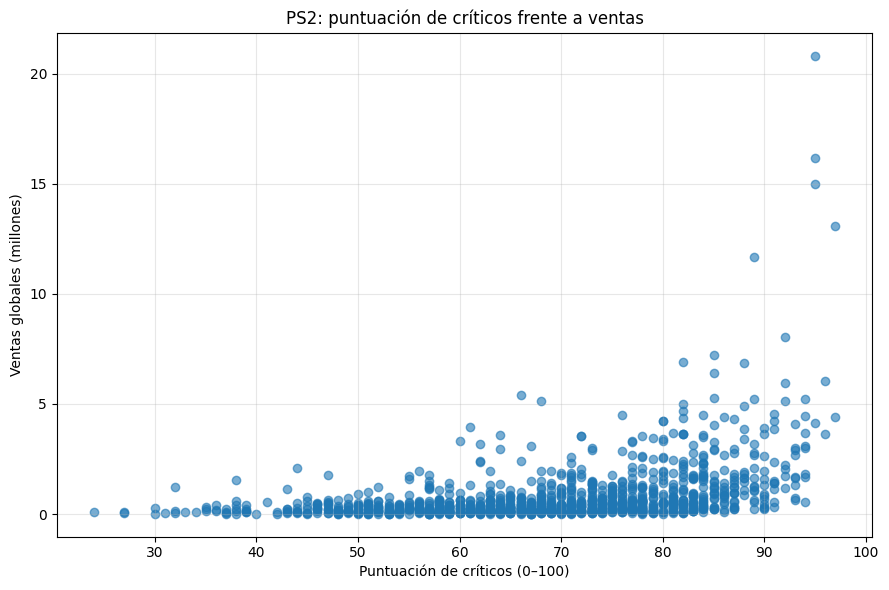

Correlación entre críticos y ventas en PS2: 0.395


In [178]:

import matplotlib.pyplot as plt

datos_criticos_ps2 = datos_ps2.dropna(
    subset=['critic_score', 'total_sales']
)

plt.figure(figsize=(9, 6))
plt.scatter(
    datos_criticos_ps2['critic_score'],
    datos_criticos_ps2['total_sales'],
    alpha=0.6
)

plt.title('PS2: puntuación de críticos frente a ventas')
plt.xlabel('Puntuación de críticos (0–100)')
plt.ylabel('Ventas globales (millones)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

correlacion_criticos_ps2 = datos_criticos_ps2[
    ['critic_score', 'total_sales']
].corr(method='pearson').iloc[0, 1]

print(
    'Correlación entre críticos y ventas en PS2:',
    round(correlacion_criticos_ps2, 3)
)


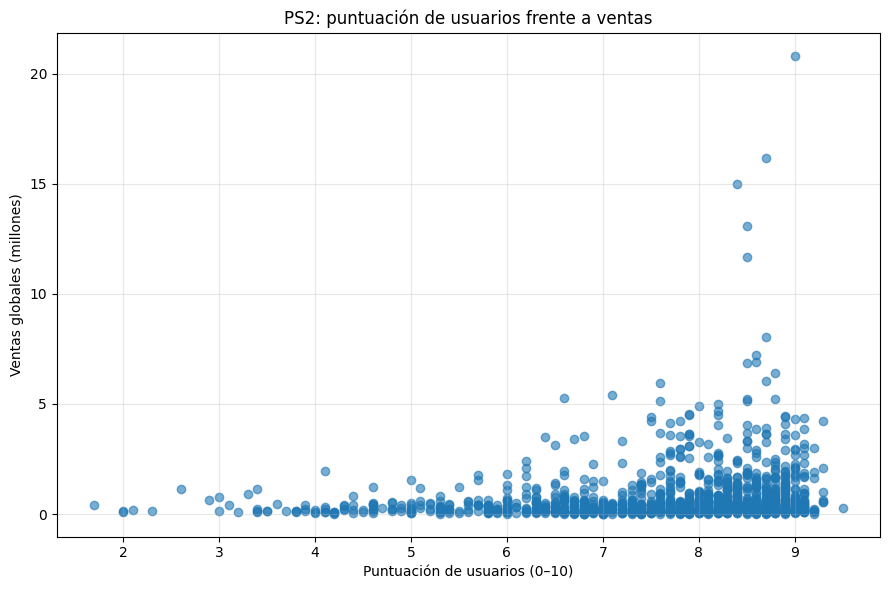

Correlación entre usuarios y ventas en PS2: 0.173


In [179]:

datos_usuarios_ps2 = datos_ps2.dropna(
    subset=['user_score_sin_tbd', 'total_sales']
)

plt.figure(figsize=(9, 6))
plt.scatter(
    datos_usuarios_ps2['user_score_sin_tbd'],
    datos_usuarios_ps2['total_sales'],
    alpha=0.6
)

plt.title('PS2: puntuación de usuarios frente a ventas')
plt.xlabel('Puntuación de usuarios (0–10)')
plt.ylabel('Ventas globales (millones)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

correlacion_usuarios_ps2 = datos_usuarios_ps2[
    ['user_score_sin_tbd', 'total_sales']
].corr(method='pearson').iloc[0, 1]

print(
    'Correlación entre usuarios y ventas en PS2:',
    round(correlacion_usuarios_ps2, 3)
)


In [180]:

# Seleccionar todos los juegos de Xbox 360
datos_x360 = df[df['platform'] == 'X360'].copy()

print('Total de registros de X360:', len(datos_x360))
print('Primer año registrado:', datos_x360['year_of_release'].min())
print('Último año registrado:', datos_x360['year_of_release'].max())

print('\nCalificaciones disponibles:')
display(
    datos_x360[
        ['total_sales', 'critic_score', 'user_score_sin_tbd']
    ].notna().sum().rename('registros_disponibles')
)


Total de registros de X360: 1262
Primer año registrado: 2005
Último año registrado: 2016

Calificaciones disponibles:


total_sales           1262
critic_score           916
user_score_sin_tbd     966
Name: registros_disponibles, dtype: int64

en esta plataforma se ve una correlacin mas fuerte entre la puntuacion y las ventas. hay muchos mas datos y se puede analizar de mejor manera. hay una correlacion mas alta (similar al caso de la plataforma Wii) entre la puntuacion de la critica y las ventas. 

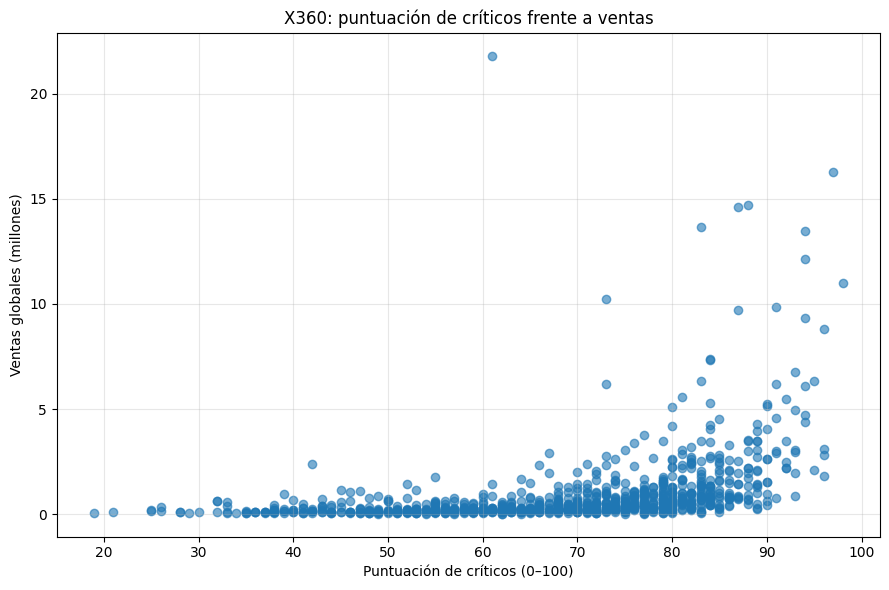

Correlación entre críticos y ventas en X360: 0.394


In [181]:

import matplotlib.pyplot as plt

datos_criticos_x360 = datos_x360.dropna(
    subset=['critic_score', 'total_sales']
)

plt.figure(figsize=(9, 6))
plt.scatter(
    datos_criticos_x360['critic_score'],
    datos_criticos_x360['total_sales'],
    alpha=0.6
)

plt.title('X360: puntuación de críticos frente a ventas')
plt.xlabel('Puntuación de críticos (0–100)')
plt.ylabel('Ventas globales (millones)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

correlacion_criticos_x360 = datos_criticos_x360[
    ['critic_score', 'total_sales']
].corr(method='pearson').iloc[0, 1]

print(
    'Correlación entre críticos y ventas en X360:',
    round(correlacion_criticos_x360, 3)
)


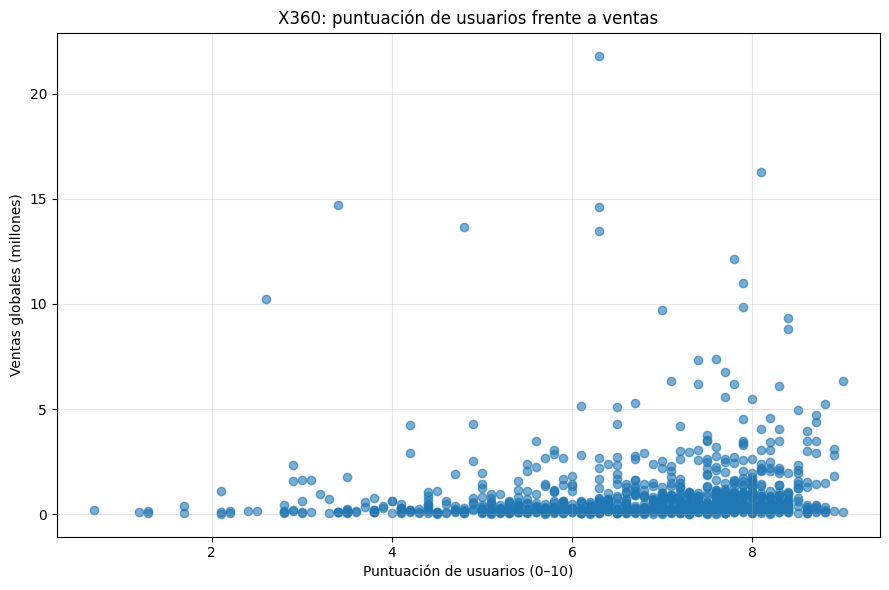

Correlación entre usuarios y ventas en X360: 0.114


In [182]:

datos_usuarios_x360 = datos_x360.dropna(
    subset=['user_score_sin_tbd', 'total_sales']
)

plt.figure(figsize=(9, 6))
plt.scatter(
    datos_usuarios_x360['user_score_sin_tbd'],
    datos_usuarios_x360['total_sales'],
    alpha=0.6
)

plt.title('X360: puntuación de usuarios frente a ventas')
plt.xlabel('Puntuación de usuarios (0–10)')
plt.ylabel('Ventas globales (millones)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

correlacion_usuarios_x360 = datos_usuarios_x360[
    ['user_score_sin_tbd', 'total_sales']
].corr(method='pearson').iloc[0, 1]

print(
    'Correlación entre usuarios y ventas en X360:',
    round(correlacion_usuarios_x360, 3)
)


In [183]:

import pandas as pd

comparacion_3_plataformas = pd.DataFrame({
    'Plataforma': ['Wii', 'PS2', 'X360'],
    'Correlacion_criticos': [
        correlacion_criticos_wii,
        correlacion_criticos_ps2,
        correlacion_criticos_x360
    ],
    'Correlacion_usuarios': [
        correlacion_usuarios_wii,
        correlacion_usuarios_ps2,
        correlacion_usuarios_x360
    ],
    'Juegos_con_criticas': [
        len(datos_criticos_wii),
        len(datos_criticos_ps2),
        len(datos_criticos_x360)
    ],
    'Juegos_con_resenas_usuarios': [
        len(datos_usuarios_wii),
        len(datos_usuarios_ps2),
        len(datos_usuarios_x360)
    ]
})

display(comparacion_3_plataformas.round(3))


,Plataforma,Correlacion_criticos,Correlacion_usuarios,Juegos_con_criticas,Juegos_con_resenas_usuarios
0,Wii,0.178,0.112,585,560
1,PS2,0.395,0.173,1298,1241
2,X360,0.394,0.114,916,966


ya comparamos 3 plataformas de las mas representativas, y los valores nos indican que la correlacion entre calificacion de usuario y ventas es positiva pero debil, mientras que la correlacion entre la calificacion de la critica ('critic_score') y las ventas es igualmente positiva y mucho mas fuerte. es mucho mas determinante la calificacion de a los criticos en cuento a las ventas alcazadas. 

In [184]:
# primero quiero identificar si hay más de una plataforma que tenga el mismo juego.
# Filtrar las tres plataformas
datos_tres_plataformas = df[
    df['platform'].isin(['Wii', 'PS2', 'X360'])
].copy()

# Contar en cuántas plataformas aparece cada juego
plataformas_por_juego = (
    datos_tres_plataformas
    .groupby('name')['platform']
    .nunique()
)

# Juegos que aparecen en las tres plataformas
juegos_compartidos = plataformas_por_juego[
    plataformas_por_juego == 3
].index

# Mostrar los juegos compartidos y sus ventas por plataforma
tabla_juegos_compartidos = (
    datos_tres_plataformas[
        datos_tres_plataformas['name'].isin(juegos_compartidos)
    ]
    .pivot_table(
        index='name',
        columns='platform',
        values='total_sales',
        aggfunc='sum'
    )
    .dropna(subset=['Wii', 'PS2', 'X360'])
)

display(tabla_juegos_compartidos.head(20))
print('Total de juegos compartidos:', len(tabla_juegos_compartidos))


platform,PS2,Wii,X360
name,,,
007: Quantum of Solace,0.43,0.65,1.48
AC/DC LIVE: Rock Band Track Pack,0.16,0.26,0.23
Alone in the Dark,0.06,0.19,0.49
Avatar: The Last Airbender - The Burning Earth,0.42,0.25,0.13
Backyard NFL Football '10,0.06,0.17,0.11
Bakugan: Battle Brawlers,0.42,0.67,0.24
Band Hero,0.41,0.97,0.79
Bee Movie Game,0.10,0.34,0.17
Ben 10 Alien Force: Vilgax Attacks,0.29,0.43,0.22


Total de juegos compartidos: 132


In [185]:

# Identificar la plataforma con mayores ventas para cada juego
plataforma_mayor_venta = tabla_juegos_compartidos[
    ['PS2', 'Wii', 'X360']
].idxmax(axis=1)

# Contar cuántos juegos lidera cada plataforma
juegos_ganados = (
    plataforma_mayor_venta
    .value_counts()
    .reindex(['PS2', 'Wii', 'X360'], fill_value=0)
    .rename_axis('platform')
    .reset_index(name='juegos_con_mayores_ventas')
)

juegos_ganados['porcentaje'] = (
    juegos_ganados['juegos_con_mayores_ventas']
    / len(tabla_juegos_compartidos) * 100
)

display(juegos_ganados.round(2))


,platform,juegos_con_mayores_ventas,porcentaje
0,PS2,35,26.52
1,Wii,52,39.39
2,X360,45,34.09


In [186]:

# Correlación entre las ventas de los mismos juegos
correlacion_ventas_plataformas = (
    tabla_juegos_compartidos[['PS2', 'Wii', 'X360']]
    .corr(method='pearson')
)

display(correlacion_ventas_plataformas.round(3))


platform,PS2,Wii,X360
platform,,,
PS2,1.000,0.567,0.538
Wii,0.567,1.000,0.680
X360,0.538,0.680,1.000


en este punto lo que se quiere es mirar la correlacion entre la olataforma y el mismo juego para mirar si la plataforma se correlaciona con la venta de los juegos. en este punto se corrio el codigo que busca determinar el numero de juegos que se vente en las tres plataformas analizadas que coinsiden con ser las mas representativas. depsues se miro la correlacion de lso 132 juegos que coinsiden cone l mismo nombre y estas tres diferentes plataformas. dando una correlacion positiva alta.  
PS2 Y Wii : correlacion positiva moderada. 
PS2 Y X360 : Correlacion positiva moderada.
Wii y X360 : Correlacion positiva moderadamente fuerte. 

en general marca una correlacion positiva. los juegos que se venden bien en una plataforma, tienden a venderce bien en otra plataform

In [187]:

datos_generos = df[
    df['year_of_release'].between(2008, 2016)
].dropna(subset=['genre', 'total_sales', 'name']).copy()

print('Años analizados: 2008–2016')
print('Total de juegos registrados:', len(datos_generos))
print(
    'Cantidad de géneros:',
    datos_generos['genre'].nunique()
)


Años analizados: 2008–2016
Total de juegos registrados: 8130
Cantidad de géneros: 12


en el punto de la relacion de genero con ventas, se queria mirar la correlacion entre genero y ventas, pero se recomienda que se haga primero una identificacion de las ventas de los diferentes generos, primero quiero hacer una presicion y ponderar los generos porque podriamos concluir que un genero solo por el hecho de presentar mas juegos es mas exitoso, cosa que puede ser mentira, y esa version se ratifica por el hecho de que hay generos con 28 juegos (Puzzle) y generos con 1031 juegos (Action). para el analisis se emplearon no la totalidad de los juegos, sino los juegos en una ventana de tiempo desde 2008 a 2016

In [188]:

resumen_generos = (
    datos_generos.groupby('genre')
    .agg(
        cantidad_juegos=('name', 'count'),
        ventas_totales=('total_sales', 'sum'),
        ventas_promedio=('total_sales', 'mean'),
        ventas_mediana=('total_sales', 'median'),
        desviacion_estandar=('total_sales', 'std'),
        ventas_maximas=('total_sales', 'max')
    )
)

resumen_generos['porcentaje_juegos'] = (
    resumen_generos['cantidad_juegos']
    / resumen_generos['cantidad_juegos'].sum() * 100
)

resumen_generos['porcentaje_ventas'] = (
    resumen_generos['ventas_totales']
    / resumen_generos['ventas_totales'].sum() * 100
)

resumen_generos['indice_ventas_por_participacion'] = (
    resumen_generos['porcentaje_ventas']
    / resumen_generos['porcentaje_juegos']
)

display(
    resumen_generos.sort_values(
        'ventas_mediana',
        ascending=False
    ).round(2)
)


,cantidad_juegos,ventas_totales,ventas_promedio,ventas_mediana,desviacion_estandar,ventas_maximas,porcentaje_juegos,porcentaje_ventas,indice_ventas_por_participacion
genre,,,,,,,,,
Shooter,583,608.19,1.04,0.34,2.14,14.73,7.17,15.70,2.19
Platform,244,195.38,0.80,0.24,2.22,28.32,3.00,5.04,1.68
Sports,958,560.34,0.58,0.20,1.54,32.77,11.78,14.46,1.23
Fighting,308,148.51,0.48,0.18,1.02,12.84,3.79,3.83,1.01
Racing,403,226.41,0.56,0.17,2.05,35.52,4.96,5.84,1.18
Action,1988,945.74,0.48,0.16,1.10,21.05,24.45,24.41,1.00
Role-Playing,783,421.57,0.54,0.16,1.30,15.13,9.63,10.88,1.13
Misc,994,396.43,0.40,0.14,1.09,21.82,12.23,10.23,0.84
Simulation,459,150.78,0.33,0.12,0.77,9.17,5.65,3.89,0.69


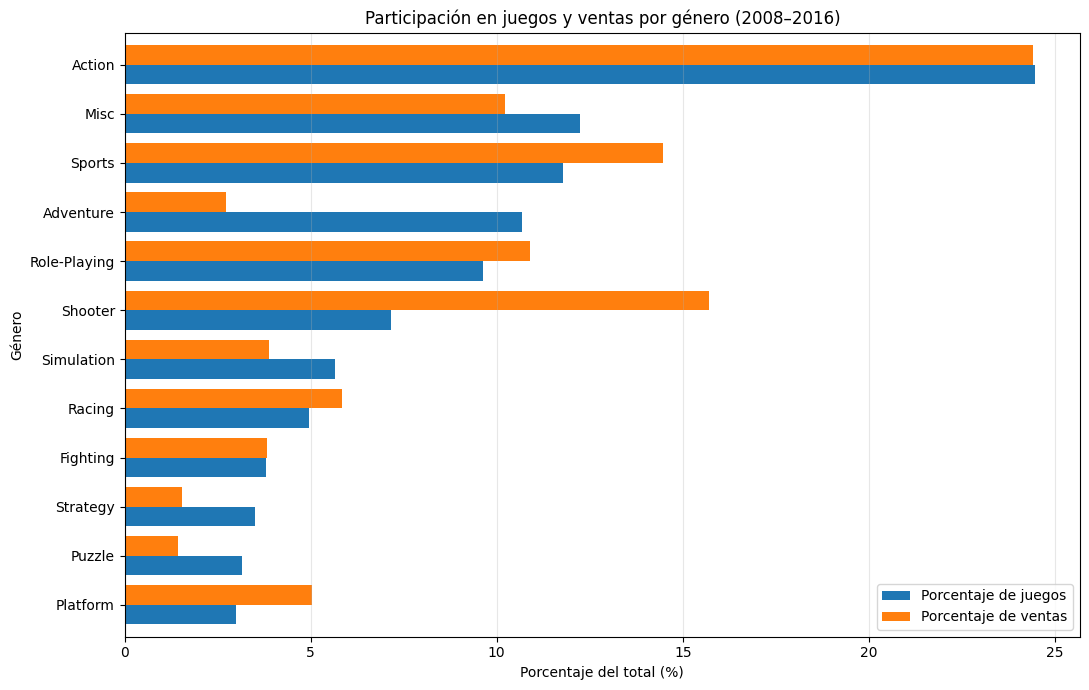

In [189]:

import matplotlib.pyplot as plt

comparacion_proporciones = resumen_generos[
    ['porcentaje_juegos', 'porcentaje_ventas']
].sort_values('porcentaje_juegos', ascending=True)

comparacion_proporciones.plot(
    kind='barh',
    figsize=(11, 7),
    width=0.8
)

plt.title('Participación en juegos y ventas por género (2008–2016)')
plt.xlabel('Porcentaje del total (%)')
plt.ylabel('Género')
plt.legend(['Porcentaje de juegos', 'Porcentaje de ventas'])
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


In [190]:

import pandas as pd
from IPython.display import display, HTML

# Configurar la visualización de Pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 25)

# Seleccionar las columnas que queremos mostrar
columnas_tabla = [
    'cantidad_juegos',
    'ventas_totales',
    'ventas_promedio',
    'ventas_mediana',
    'desviacion_estandar',
    'ventas_maximas',
    'porcentaje_juegos',
    'porcentaje_ventas',
    'indice_ventas_por_participacion'
]

# Redondear los valores y mostrar la tabla completa
tabla_final_generos = (
    resumen_generos[columnas_tabla]
    .round(2)
    .reset_index()
)

display(
    HTML(
        tabla_final_generos.to_html(
            index=False,
            border=0,
            justify='center',
            classes='tabla-generos'
        )
    )
)


genre,cantidad_juegos,ventas_totales,ventas_promedio,ventas_mediana,desviacion_estandar,ventas_maximas,porcentaje_juegos,porcentaje_ventas,indice_ventas_por_participacion
Action,1988,945.74,0.48,0.16,1.10,21.05,24.45,24.41,1.00
Adventure,869,105.86,0.12,0.04,0.28,3.17,10.69,2.73,0.26
Fighting,308,148.51,0.48,0.18,1.02,12.84,3.79,3.83,1.01
Misc,994,396.43,0.40,0.14,1.09,21.82,12.23,10.23,0.84
Platform,244,195.38,0.80,0.24,2.22,28.32,3.00,5.04,1.68
Puzzle,257,55.62,0.22,0.09,0.42,3.26,3.16,1.44,0.45
Racing,403,226.41,0.56,0.17,2.05,35.52,4.96,5.84,1.18
Role-Playing,783,421.57,0.54,0.16,1.30,15.13,9.63,10.88,1.13
Shooter,583,608.19,1.04,0.34,2.14,14.73,7.17,15.70,2.19
Simulation,459,150.78,0.33,0.12,0.77,9.17,5.65,3.89,0.69


con el anterior cuadro se demuestra como juegos de pocos titulos pueden representar mayores ventas, con este ajuste se busca identificar el genero que mas dinero proporciona sin tener en cuenta el numeri de titulos. en la literatura encontre que la correlacion de pearson no es indicada por ser una variable categorica con una numerica, propone otras pruebas pero en realidad creo que con esa indice ya miramos la relacion entre el genero y las ventas sin tener en cuenta el total de ventas pues en realidad estariamos mirando con mayor valor los generos que muestran mas titulos y pasaria a un segundo plano el genero como tal. 
En el caso anterior Shooter representa el 15.70 % de las ventas, y el 7.17% de los titulos, por eso el indice se redondea en 2.19.
La grafica de barras es muy diciente y podria ser una buena manera de mirar el comportamiento de las ventas y la participacion de los mismos con respecto al numero de juegos que se lanzan. en la grafica podriamos mirar si juntas barras son similares, podria decir que las ventas pueden deberse al numero de juegos, si es mas grande el porcentaje de participacion de lanzamientos y menor el porcentaje de participacion en las ventas, podria determinar que con mayuor numero de juegos a disposicion de los consumidores, no logran impactar de manera proporcional el numero de las vrntas, y si al contrario (como es el caso del genero Shooter) que la participacion en las ventas sea baja, osea proporcionalmente es inferior la participacion en cuanto a numero de lanzamientos y la participacion en las ventas es alto, osea que más juegos son exitosos. podria ser una buena practica estudiar más a fondo este fenomeno, porque una hipotesis podria ser implementar mas lanzamientos de este genero por su excelente comportamiento en ventas. 

In [191]:

datos_regionales = df[
    df['year_of_release'].between(2008, 2016)
].copy()
ventas_plataforma_region = datos_regionales.groupby('platform')[
    ['na_sales', 'eu_sales', 'jp_sales']
].sum()

ventas_plataforma_region.head(31)


,na_sales,eu_sales,jp_sales
platform,,,
3DS,82.65,61.27,100.62
DC,0.00,0.00,0.04
DS,198.73,86.13,76.12
PC,41.07,92.17,0.00
PS2,32.91,14.24,8.47
PS3,349.13,293.73,74.11
PS4,108.74,141.09,15.96
PSP,34.04,26.21,60.46
PSV,12.47,13.07,21.84


In [192]:
top_5_na = ventas_plataforma_region['na_sales'].sort_values(
    ascending=False
).head(5)

top_5_eu = ventas_plataforma_region['eu_sales'].sort_values(
    ascending=False
).head(5)

top_5_jp = ventas_plataforma_region['jp_sales'].sort_values(
    ascending=False
).head(5)

print("Norteamérica")
display(top_5_na)

print("Europa")
display(top_5_eu)

print("Japón")
display(top_5_jp)

Norteamérica


platform
X360    490.69
PS3     349.13
Wii     332.87
DS      198.73
PS4     108.74
Name: na_sales, dtype: float64

Europa


platform
PS3     293.73
X360    234.88
Wii     170.74
PS4     141.09
PC       92.17
Name: eu_sales, dtype: float64

Japón


platform
3DS    100.62
DS      76.12
PS3     74.11
PSP     60.46
Wii     47.01
Name: jp_sales, dtype: float64

ahora obtenemos la cuota de mercado de cada una

In [193]:
# Ventas totales de cada región
ventas_totales_region = datos_regionales[
    ['na_sales', 'eu_sales', 'jp_sales']
].sum()

# Cuotas de mercado de las cinco plataformas principales
cuota_na = (top_5_na / ventas_totales_region['na_sales']) * 100
cuota_eu = (top_5_eu / ventas_totales_region['eu_sales']) * 100
cuota_jp = (top_5_jp / ventas_totales_region['jp_sales']) * 100

# Unir los resultados en una tabla comparativa
tabla_cuotas = pd.concat(
    [cuota_na, cuota_eu, cuota_jp],
    axis=1
)

tabla_cuotas.columns = [
    'Norteamérica (%)',
    'Europa (%)',
    'Japón (%)'
]

tabla_cuotas.round(2)

,Norteamérica (%),Europa (%),Japón (%)
platform,,,
X360,27.04,19.41,NaN
PS3,19.24,24.27,17.34
Wii,18.34,14.11,11.00
DS,10.95,NaN,17.82
PS4,5.99,11.66,NaN
PC,NaN,7.62,NaN
3DS,NaN,NaN,23.55
PSP,NaN,NaN,14.15


para hacer más grafica la imagen de analisis, quiero hacer una grafica de barras que nos pueda mostrar de mejor manera como se comportan las ventas y un dato adicional, quiero hacer una tabla que muestre como es la participacion de cada una de las regiones en las ventas totales. 

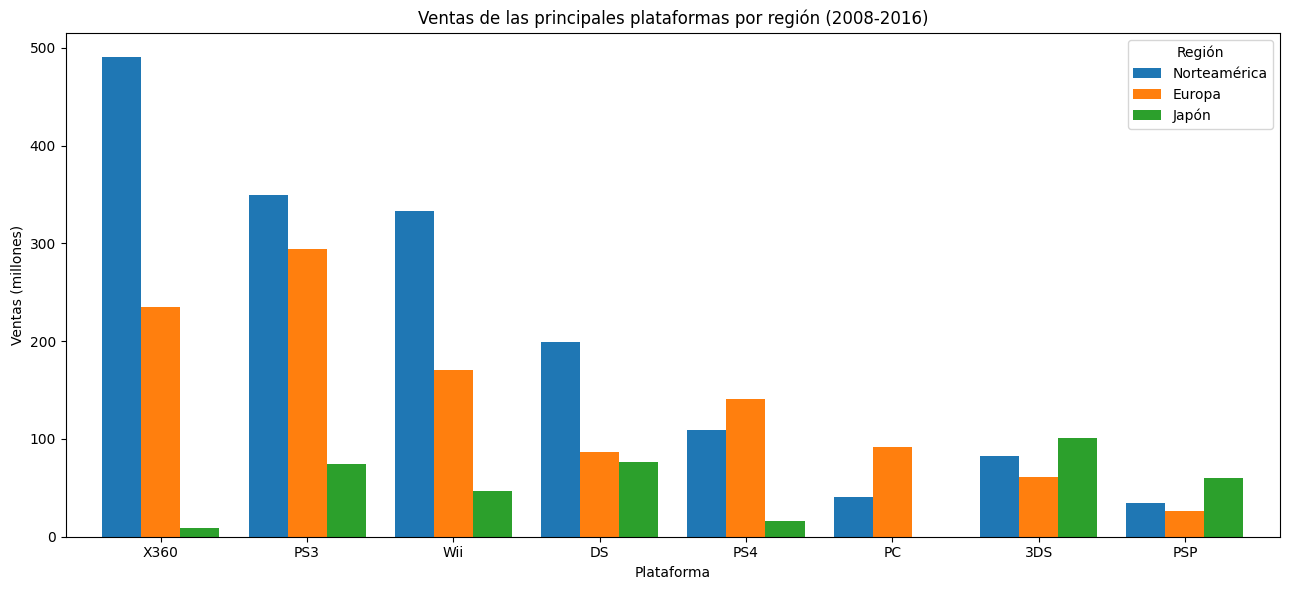

In [194]:

# Comparar las ventas de las plataformas entre regiones

import matplotlib.pyplot as plt

ventas_plataformas_grafica = ventas_plataforma_region.loc[
    tabla_cuotas.index
]

ax = ventas_plataformas_grafica.plot(
    kind='bar',
    figsize=(13, 6),
    width=0.8
)

ax.set_title('Ventas de las principales plataformas por región (2008-2016)')
ax.set_xlabel('Plataforma')
ax.set_ylabel('Ventas (millones)')
ax.legend(['Norteamérica', 'Europa', 'Japón'], title='Región')
ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()


In [195]:

# Participación regional durante todos los años disponibles

ventas_totales_por_region = df[
    ['na_sales', 'eu_sales', 'jp_sales', 'other_sales']
].sum()

# Calcular la participación de cada región
participacion_regional = (
    ventas_totales_por_region / ventas_totales_por_region.sum()
) * 100

# Crear una tabla de resultados
tabla_participacion_regional = pd.DataFrame({
    'Ventas totales (millones)': ventas_totales_por_region,
    'Participación (%)': participacion_regional
})

tabla_participacion_regional.round(2)


,Ventas totales (millones),Participación (%)
na_sales,4402.35,49.38
eu_sales,2424.67,27.20
jp_sales,1297.37,14.55
other_sales,791.32,8.88


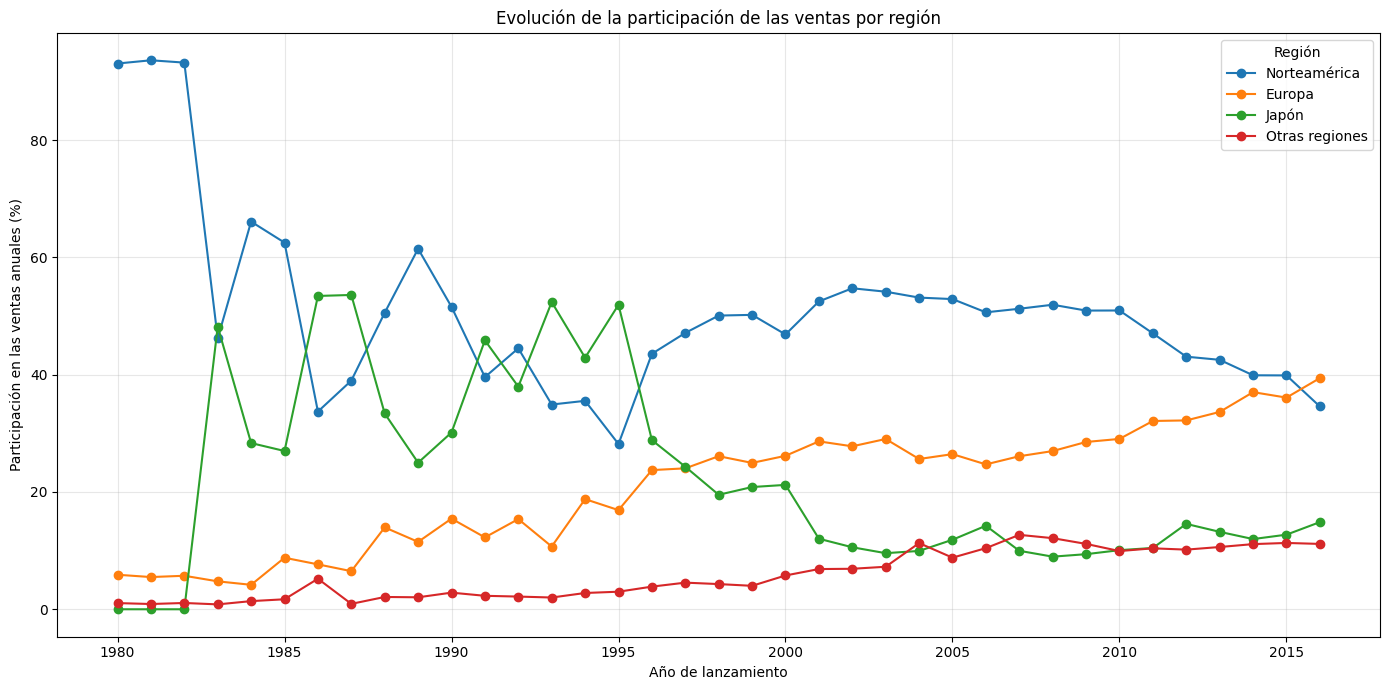

In [196]:

# Calcular las ventas por año para las cuatro regiones

ventas_region_año = df.groupby('year_of_release')[
    ['na_sales', 'eu_sales', 'jp_sales', 'other_sales']
].sum()

# Calcular las ventas totales de cada año
ventas_totales_año = ventas_region_año.sum(axis=1)

# Calcular la participación porcentual de cada región por año
participacion_region_año = (
    ventas_region_año.div(ventas_totales_año, axis=0) * 100
)

# Graficar la evolución de la participación regional
ax = participacion_region_año.plot(
    kind='line',
    figsize=(14, 7),
    marker='o'
)

ax.set_title('Evolución de la participación de las ventas por región')
ax.set_xlabel('Año de lanzamiento')
ax.set_ylabel('Participación en las ventas anuales (%)')
ax.legend(
    ['Norteamérica', 'Europa', 'Japón', 'Otras regiones'],
    title='Región'
)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


con la grafica anterior se logra determinar como mientras los mercados de Japon y Norteamerica estan mostrando una disminucion, los mercados de Europa y otras partes muestran un incremento, podria ser una biena medida si se quiere iniciar una campaña para el año siguiente. podria ser una bena determinante para la eleccion de las plataformas tamnbien, pues se podria pensar en el impulsode las plataformas que son más exitosas en ventas en regiones como la europea y otras partes, por su crecimeinto en ventas. al igual no dejaria de lado el mercado de norteamerica, que si bien no reporta aumento en ventas si muestra una estabilidad que podria dar un parte de seguridad en cualquier campaña por mostrarce como un mercado estable y con muy buenos numeros. 

ahora se quiere identificar cuales osn los 5 generos que más se venden en la sdiferentes regiones, teniendo en cuenta que las ventas de otras regioes son similares a las de Japon en un segundo codigo quiero comparar tambien other_sales. 

In [197]:

# Ventas totales por género en cada región

ventas_genero_region = datos_regionales.groupby('genre')[
    ['na_sales', 'eu_sales', 'jp_sales']
].sum()

# Cinco géneros con mayores ventas en cada región

top_5_generos_na = ventas_genero_region['na_sales'].sort_values(
    ascending=False
).head(5)

top_5_generos_eu = ventas_genero_region['eu_sales'].sort_values(
    ascending=False
).head(5)

top_5_generos_jp = ventas_genero_region['jp_sales'].sort_values(
    ascending=False
).head(5)

print("Norteamérica")
display(top_5_generos_na)

print("Europa")
display(top_5_generos_eu)

print("Japón")
display(top_5_generos_jp)



Norteamérica


genre
Action          433.74
Shooter         311.26
Sports          276.27
Misc            211.61
Role-Playing    155.81
Name: na_sales, dtype: float64

Europa


genre
Action          310.59
Shooter         208.35
Sports          185.19
Misc            107.00
Role-Playing     94.46
Name: eu_sales, dtype: float64

Japón


genre
Role-Playing    138.12
Action           90.16
Misc             37.33
Sports           30.69
Adventure        23.36
Name: jp_sales, dtype: float64

In [198]:


# Ventas por género en las tres regiones
ventas_genero_region = datos_regionales.groupby('genre')[
    ['na_sales', 'eu_sales', 'jp_sales']
].sum()

# Top 5 géneros de cada región
top_5_generos_3_regiones = pd.DataFrame({
    'Norteamérica': ventas_genero_region['na_sales'].nlargest(5),
    'Europa': ventas_genero_region['eu_sales'].nlargest(5),
    'Japón': ventas_genero_region['jp_sales'].nlargest(5)
})

display(top_5_generos_3_regiones.round(2))


,Norteamérica,Europa,Japón
genre,,,
Action,433.74,310.59,90.16
Adventure,NaN,NaN,23.36
Misc,211.61,107.00,37.33
Role-Playing,155.81,94.46,138.12
Shooter,311.26,208.35,NaN
Sports,276.27,185.19,30.69


In [199]:

# Ventas por género en las cuatro regiones
ventas_genero_4_regiones = datos_regionales.groupby('genre')[
    ['na_sales', 'eu_sales', 'jp_sales', 'other_sales']
].sum()

# Top 5 géneros de cada región
top_5_generos_4_regiones = pd.DataFrame({
    'Norteamérica': ventas_genero_4_regiones['na_sales'].nlargest(5),
    'Europa': ventas_genero_4_regiones['eu_sales'].nlargest(5),
    'Japón': ventas_genero_4_regiones['jp_sales'].nlargest(5),
    'Otras regiones': ventas_genero_4_regiones['other_sales'].nlargest(5)
})

display(top_5_generos_4_regiones.round(2))


,Norteamérica,Europa,Japón,Otras regiones
genre,,,,
Action,433.74,310.59,90.16,111.25
Adventure,NaN,NaN,23.36,NaN
Misc,211.61,107.00,37.33,40.49
Role-Playing,155.81,94.46,138.12,33.18
Shooter,311.26,208.35,NaN,72.65
Sports,276.27,185.19,30.69,68.19


los numeros de ventas para las regiones denominadas otras regiones, muestran unos valores interesantes para la identificacion de potenciales nichos de mercado, yo no me centraria en solo las 3 regiones para poder tomar las desiciones. 

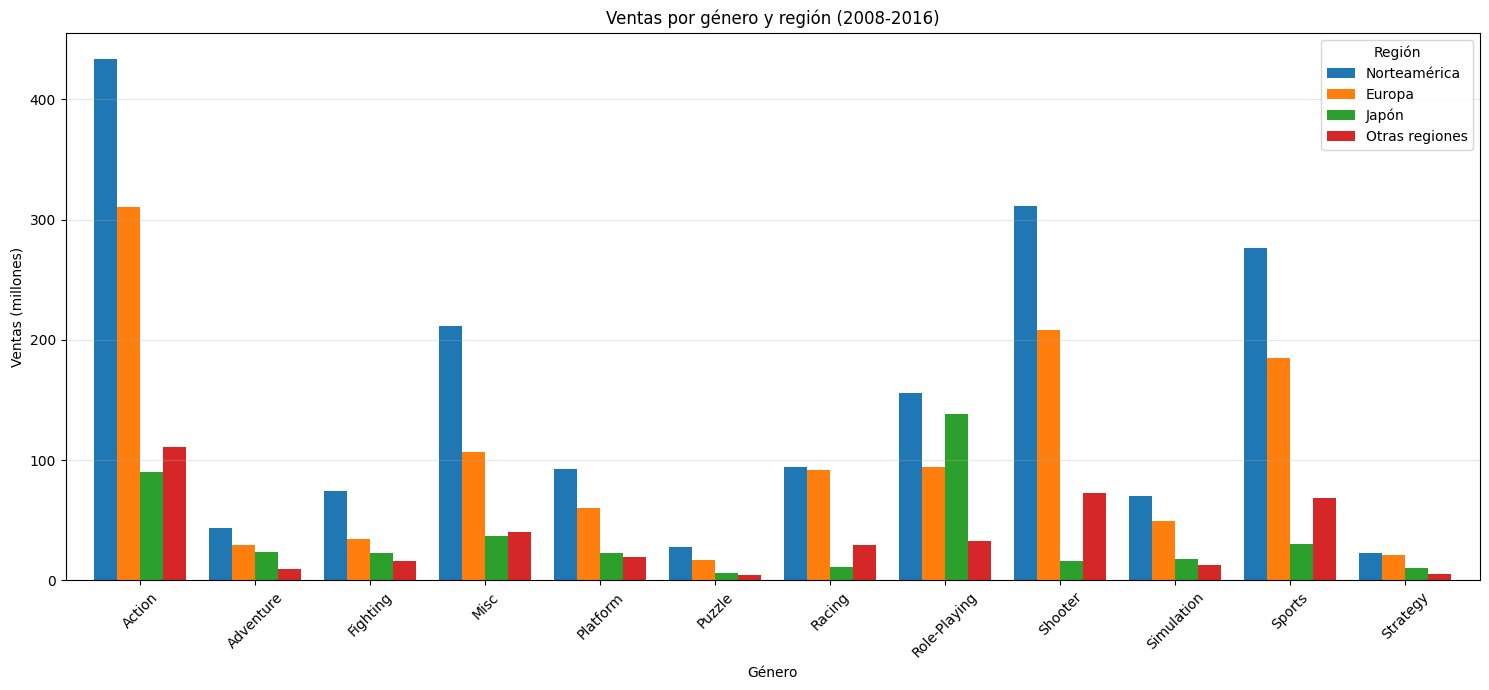

In [200]:

# Gráfica de ventas de todos los géneros en las cuatro regiones
ax = ventas_genero_4_regiones.plot(
    kind='bar',
    figsize=(15, 7),
    width=0.8
)

ax.set_title('Ventas por género y región (2008-2016)')
ax.set_xlabel('Género')
ax.set_ylabel('Ventas (millones)')
ax.legend(
    ['Norteamérica', 'Europa', 'Japón', 'Otras regiones'],
    title='Región'
)
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


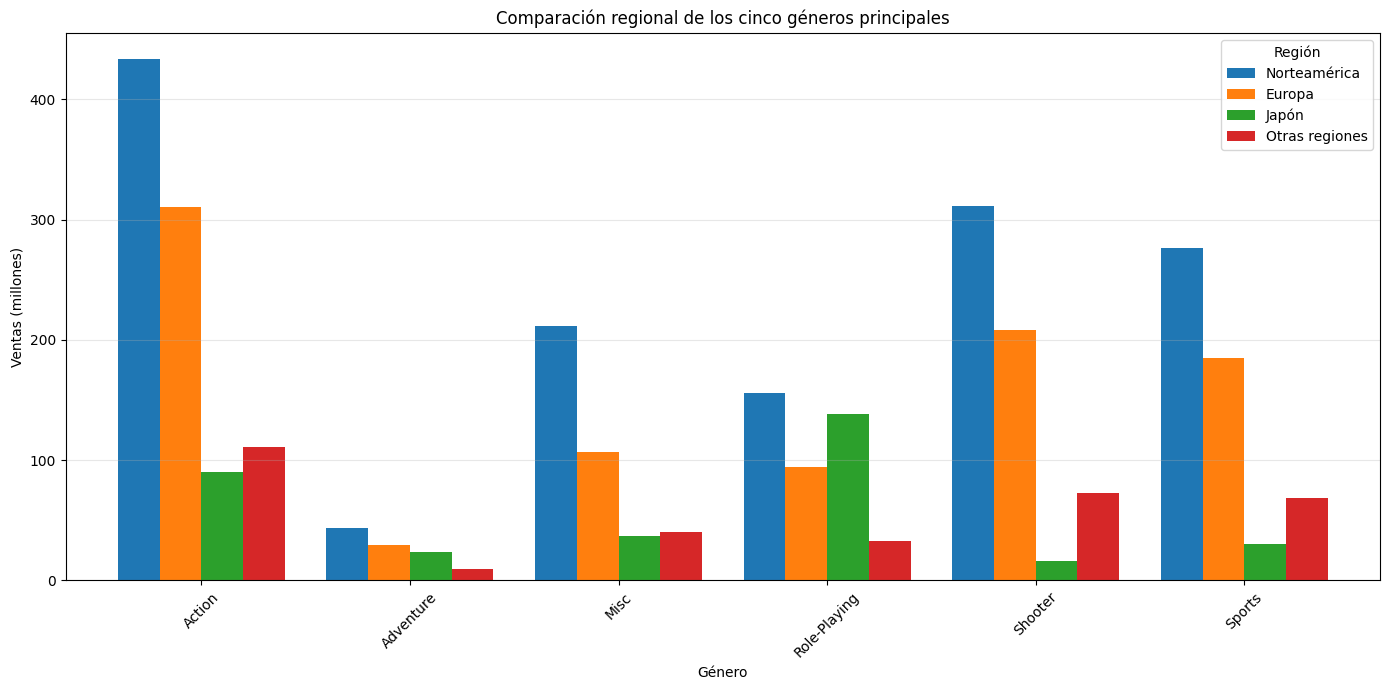

In [201]:

# Identificar los cinco géneros principales de cada región
top_generos_por_region = {
    'Norteamérica': ventas_genero_4_regiones['na_sales'].nlargest(5).index,
    'Europa': ventas_genero_4_regiones['eu_sales'].nlargest(5).index,
    'Japón': ventas_genero_4_regiones['jp_sales'].nlargest(5).index,
    'Otras regiones': ventas_genero_4_regiones['other_sales'].nlargest(5).index
}

# Reunir los géneros que aparecen en al menos un top 5
generos_top_5 = sorted(set().union(*top_generos_por_region.values()))

# Seleccionar las ventas de esos géneros en las cuatro regiones
ventas_top_generos = ventas_genero_4_regiones.loc[generos_top_5]

# Graficar la comparación
ax = ventas_top_generos.plot(
    kind='bar',
    figsize=(14, 7),
    width=0.8
)

ax.set_title('Comparación regional de los cinco géneros principales')
ax.set_xlabel('Género')
ax.set_ylabel('Ventas (millones)')
ax.legend(
    ['Norteamérica', 'Europa', 'Japón', 'Otras regiones'],
    title='Región'
)
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


es interesante ver como las ventas de genero de action y en la region de Norteamerica, muestran numeros de ventas superiores. ahora qwuiero saber si las diferencias entre las ventas de Action y Shooter son estadisticamente significativas

In [202]:
from scipy.stats import mannwhitneyu

# Obtener las ventas de cada género
ventas_action = datos_regionales.loc[
    datos_regionales['genre'] == 'Action',
    'total_sales'
].dropna()

ventas_shooter = datos_regionales.loc[
    datos_regionales['genre'] == 'Shooter',
    'total_sales'
].dropna()

# Ejecutar la prueba U de Mann-Whitney
estadistico_u, valor_p = mannwhitneyu(
    ventas_action,
    ventas_shooter,
    alternative='two-sided'
)

# Mostrar resultados
print("Videojuegos Action:", len(ventas_action))
print("Videojuegos Shooter:", len(ventas_shooter))
print("Mediana de ventas Action:", ventas_action.median())
print("Mediana de ventas Shooter:", ventas_shooter.median())
print("Estadístico U:", estadistico_u)
print("Valor p:", valor_p)

# Interpretar el resultado
alfa = 0.05

if valor_p < alfa:
    print("Se rechaza H0: hay evidencia de diferencias significativas.")
else:
    print("No se rechaza H0: no hay evidencia suficiente de diferencias significativas.")

Videojuegos Action: 1988
Videojuegos Shooter: 583
Mediana de ventas Action: 0.16000000000000003
Mediana de ventas Shooter: 0.33999999999999997
Estadístico U: 451624.0
Valor p: 4.801980799510126e-16
Se rechaza H0: hay evidencia de diferencias significativas.


Esta mediana nos puede indicar que si bien los juegos del genero Shooter muestran mahores ventas medias, el gran numero de lanzamientos de Action galonan el total de las ventas que superan las ventas de Shooter con una mediana aun más alta.  

Para mirar si las clasificaciones de ESRB afectan a las ventas en regiones individuales se deben comparar las ventas por clasificacion ESRB para als tres regiones, se calcularan numero de videojuegos, ventas totales , media y medianapara cada clasificacion. 

In [203]:

# Ventas por clasificación ESRB en 2008-2016

datos_esrb = datos_regionales.dropna(
    subset=['rating']
).copy()

resumen_esrb = datos_esrb.groupby('rating').agg(
    cantidad_juegos=('name', 'count'),
    ventas_na_totales=('na_sales', 'sum'),
    ventas_eu_totales=('eu_sales', 'sum'),
    ventas_jp_totales=('jp_sales', 'sum'),
    ventas_other_totales=('other_sales', 'sum'),
    mediana_na=('na_sales', 'median'),
    mediana_eu=('eu_sales', 'median'),
    mediana_jp=('jp_sales', 'median'),
    mediana_other=('other_sales', 'median')
)

display(resumen_esrb.round(3))


,cantidad_juegos,ventas_na_totales,ventas_eu_totales,ventas_jp_totales,ventas_other_totales,mediana_na,mediana_eu,mediana_jp,mediana_other
rating,,,,,,,,,
E,1823,536.93,326.61,77.17,110.39,0.11,0.02,0.0,0.020
E10+,980,251.88,144.53,25.67,52.00,0.12,0.05,0.0,0.020
EC,6,1.32,0.00,0.00,0.08,0.23,0.00,0.0,0.015
M,933,502.60,362.65,39.33,123.88,0.16,0.14,0.0,0.040
RP,1,0.00,0.03,0.00,0.01,0.00,0.03,0.0,0.010
T,1362,303.41,187.62,64.51,75.65,0.10,0.04,0.0,0.020


luego quiero hacer una prueba estadistica para determinar con una prueba Kruskal_Wallis si las ventas son iguales entre las clasificaciones o como hipotesis alterna mirar si almenos una clasificacion presenta una distribucion diferente. 

In [204]:

from scipy.stats import kruskal

# Columnas de ventas regionales
columnas_regiones = {
    'Norteamérica': 'na_sales',
    'Europa': 'eu_sales',
    'Japón': 'jp_sales',
    'Otras regiones': 'other_sales'
}

resultados_esrb = []

for region, columna in columnas_regiones.items():

    datos_region = datos_esrb[
        [columna, 'rating']
    ].dropna()

    grupos = [
        grupo[columna].values
        for _, grupo in datos_region.groupby('rating')
        if len(grupo) > 0
    ]

    estadistico_h, valor_p = kruskal(*grupos)

    resultados_esrb.append({
        'Región': region,
        'Estadístico H': estadistico_h,
        'Valor p': valor_p,
        'Diferencia significativa': valor_p < 0.05
    })

tabla_pruebas_esrb = pd.DataFrame(resultados_esrb)

display(tabla_pruebas_esrb.round(6))


,Región,Estadístico H,Valor p,Diferencia significativa
0,Norteamérica,76.506784,0.0,True
1,Europa,428.136834,0.0,True
2,Japón,410.481795,0.0,True
3,Otras regiones,189.643748,0.0,True


hay evidencia estadística de que las distribuciones de ventas no son iguales para todas las clasificaciones en ninguna de las cuatro regiones. Ahora se quiere mirar como se comportan las ventas en las diferentes regiones y en laas distinas clasificaciones

In [205]:
# Ordenar las clasificaciones por mediana de ventas en cada región

for region, columna in columnas_regiones.items():
    print(f"\n{region}")

    resumen_region = datos_esrb.groupby('rating').agg(
        cantidad_juegos=('name', 'count'),
        ventas_totales=(columna, 'sum'),
        ventas_mediana=(columna, 'median'),
        ventas_promedio=(columna, 'mean')
    ).sort_values(
        'ventas_mediana', ascending=False
    )

    display(resumen_region.round(3))


Norteamérica


,cantidad_juegos,ventas_totales,ventas_mediana,ventas_promedio
rating,,,,
EC,6,1.32,0.23,0.220
M,933,502.60,0.16,0.539
E10+,980,251.88,0.12,0.257
E,1823,536.93,0.11,0.295
T,1362,303.41,0.10,0.223
RP,1,0.00,0.00,0.000



Europa


,cantidad_juegos,ventas_totales,ventas_mediana,ventas_promedio
rating,,,,
M,933,362.65,0.14,0.389
E10+,980,144.53,0.05,0.147
T,1362,187.62,0.04,0.138
RP,1,0.03,0.03,0.030
E,1823,326.61,0.02,0.179
EC,6,0.00,0.00,0.000



Japón


,cantidad_juegos,ventas_totales,ventas_mediana,ventas_promedio
rating,,,,
E,1823,77.17,0.0,0.042
E10+,980,25.67,0.0,0.026
EC,6,0.00,0.0,0.000
M,933,39.33,0.0,0.042
RP,1,0.00,0.0,0.000
T,1362,64.51,0.0,0.047



Otras regiones


,cantidad_juegos,ventas_totales,ventas_mediana,ventas_promedio
rating,,,,
M,933,123.88,0.040,0.133
E,1823,110.39,0.020,0.061
E10+,980,52.00,0.020,0.053
T,1362,75.65,0.020,0.056
EC,6,0.08,0.015,0.013
RP,1,0.01,0.010,0.010


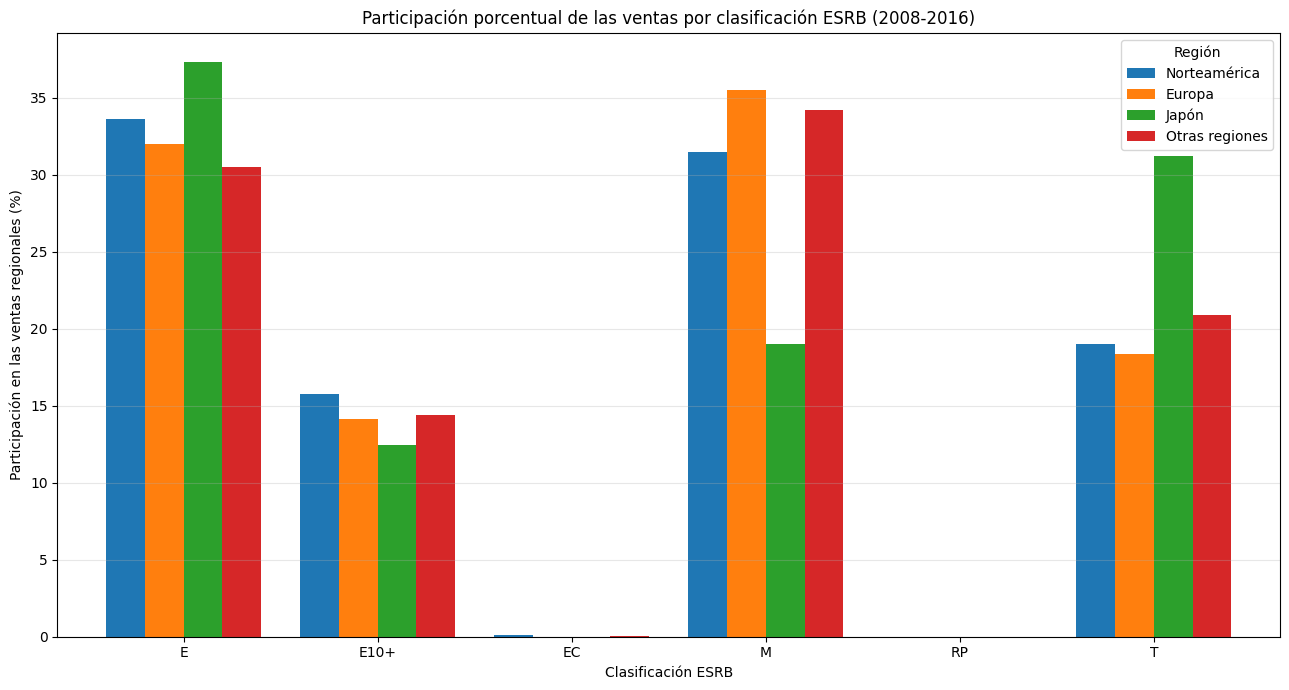

In [206]:

# Ventas totales por clasificación ESRB en cada región
ventas_esrb_region = datos_esrb.groupby('rating')[
    ['na_sales', 'eu_sales', 'jp_sales', 'other_sales']
].sum()

# Calcular la participación porcentual dentro de cada región
participacion_esrb_region = (
    ventas_esrb_region.div(ventas_esrb_region.sum(axis=0), axis=1) * 100
)

# Crear la gráfica de barras agrupadas
ax = participacion_esrb_region.plot(
    kind='bar',
    figsize=(13, 7),
    width=0.8
)

ax.set_title('Participación porcentual de las ventas por clasificación ESRB (2008-2016)')
ax.set_xlabel('Clasificación ESRB')
ax.set_ylabel('Participación en las ventas regionales (%)')
ax.legend(
    ['Norteamérica', 'Europa', 'Japón', 'Otras regiones'],
    title='Región'
)
ax.tick_params(axis='x', rotation=0)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


Con la anterior grafica se puede determinar que la clasificacion afecta las ventas en las diferentes regiones, pero se determina que hay un mayor impacto en las diferentes regiones, los juegos en Japon demuestran un mayor nival de ventas en la clasificacion E al igual que Norteamerca. mientras que en otras regiones cmuestran un ,mayor exito en ventas con la claficiacion 'M' al igual que Europa. es interesante tambnien mirar la mediana mara determinar cual de las clasificaciones tiene un mejor valor medio las cuales son mejores para Europa, norteamerica y otras partes se logra con la clasificacion 'M', 

ahora se procede a laas pruebas de las hipotesis. 
— Las calificaciones promedio de los usuarios para las plataformas Xbox One y PC son las mismas.


In [207]:

from scipy.stats import ttest_ind

# Obtener las calificaciones de cada plataforma
calificaciones_xbox = datos_regionales.loc[
    datos_regionales['platform'] == 'XOne',
    'user_score_sin_tbd'
].dropna()

calificaciones_pc = datos_regionales.loc[
    datos_regionales['platform'] == 'PC',
    'user_score_sin_tbd'
].dropna()

# Estadísticas descriptivas
print("Xbox One")
print("Cantidad:", len(calificaciones_xbox))
print("Media:", calificaciones_xbox.mean())
print("Mediana:", calificaciones_xbox.median())

print("\nPC")
print("Cantidad:", len(calificaciones_pc))
print("Media:", calificaciones_pc.mean())
print("Mediana:", calificaciones_pc.median())

# Prueba t de Welch
estadistico_t, valor_p = ttest_ind(
    calificaciones_xbox,
    calificaciones_pc,
    equal_var=False,
    alternative='two-sided'
)

print("\nEstadístico t:", estadistico_t)
print("Valor p:", valor_p)

# Decisión estadística
alfa = 0.05

if valor_p < alfa:
    print("Se rechaza H0: las medias presentan una diferencia significativa.")
else:
    print("No se rechaza H0: no hay evidencia suficiente de una diferencia entre las medias.")



Xbox One
Cantidad: 182
Media: 6.521428571428572
Mediana: 6.8

PC
Cantidad: 515
Media: 6.71747572815534
Mediana: 7.1

Estadístico t: -1.597241478935328
Valor p: 0.11111296036738474
No se rechaza H0: no hay evidencia suficiente de una diferencia entre las medias.


con una significancia de 0.05 y un valor p de 0.11111296036738474 (mayor a 0.05) se puede determinar que no  diferencias estadisticamente significativas entre las calificaciones promedios de los usuarios de las plataformas Xbox One y PC. 

 Las calificaciones promedio de los usuarios para los géneros de Acción y Deportes son diferentes.

Establece tu mismo el valor de umbral alfa.

Explica:

— Cómo formulaste las hipótesis nula y alternativa.

— Qué criterio utilizaste para probar las hipótesis y por qué.

para esta voy a emplear un nivel de significancia de 0.05, como se venia manejando, que es lo aprendido y como he venido manejando las diferentes hipotesis. voy a usar la coluna que cree de la calificacion sin tbd, y voy a utilizar la misma ventana de tiempo que he venido empleando que es desde el 2008 al 2012, que se tomo ya que la vida media de las diferentes plataformas rondaban entre los 4 y los 12 años, con ello se quiere incluir la spaltaformas que estan en crecimiento, las que estan estables y las que estan en disminucion. hasta el dia de corte que es en el a{ño 2016. la hipotesis nula plantea que las calificaciones promedios de los usuarios para los generos accion y Deportes son iguales. se empleo la prueba de t de Welch para dos muestras independientes como la literatura lo aconsejo. 

In [208]:

from scipy.stats import ttest_ind

# Obtener las calificaciones de los videojuegos de Acción
calificaciones_accion = datos_regionales.loc[
    datos_regionales['genre'] == 'Action',
    'user_score_sin_tbd'
].dropna()

# Obtener las calificaciones de los videojuegos de Deportes
calificaciones_deportes = datos_regionales.loc[
    datos_regionales['genre'] == 'Sports',
    'user_score_sin_tbd'
].dropna()

# Mostrar estadísticas descriptivas
print("Género Acción")
print("Cantidad:", len(calificaciones_accion))
print("Media:", calificaciones_accion.mean())
print("Desviación estándar:", calificaciones_accion.std())

print("\nGénero Deportes")
print("Cantidad:", len(calificaciones_deportes))
print("Media:", calificaciones_deportes.mean())
print("Desviación estándar:", calificaciones_deportes.std())

# Prueba t de Welch
estadistico_t, valor_p = ttest_ind(
    calificaciones_accion,
    calificaciones_deportes,
    equal_var=False,
    alternative='two-sided'
)

# Mostrar resultados
alfa = 0.05

print("\nEstadístico t:", estadistico_t)
print("Valor p:", valor_p)
print("Alfa:", alfa)

if valor_p < alfa:
    print("Se rechaza H0: las medias son significativamente diferentes.")
else:
    print("No se rechaza H0: no hay evidencia suficiente de diferencias entre las medias.")


Género Acción
Cantidad: 1080
Media: 6.854444444444444
Desviación estándar: 1.3421652193594045

Género Deportes
Cantidad: 498
Media: 6.215863453815261
Desviación estándar: 1.7108863639446394

Estadístico t: 7.351313023483934
Valor p: 4.910932152133621e-13
Alfa: 0.05
Se rechaza H0: las medias son significativamente diferentes.


La calificacion promedio para Action fue de 6.85 puntos, mientras que la de deportes fue de 6.22. para este analisis se excluyen los valores tbd y los ausentes, y se tienen en cuenta solo los que tienen valores numericos aceotables. que ya fueron determinados en la columna que se creo altena al df original. 
con un valor p de 4.910932152133621e-13 de puede rechazar la hipotesis nula y se determina que las calificaciones promedio entre los generos Action y Deportes son estadiscticamente diferentes para los periodos de 2008 y 2016. 

como conclusion general el empleo de las diferentes tecnicas de analisis de datos muestra una herramiente indispensable para la toma de desiciones, se t¿determina que el comportamiento de las diferentes metricas, son mucho mas complejas de lo normal, y que hay que profundizar al maximo para llegar a desiciones acertadas. 
en la determinacion de las regiones me llamo la atencion ver como proporcionalemnte los mercados de otras partes del mundo no encerrados entre las rergiones de Europa, Norteramerica y Japon, van ganando precensia en el mercado y asumo que con el animo de tomar desicines en el mercado de las plataformas de juegos, las preferencias de otros lugares del mundo se deben tener en cuenta pues muestran un crecimiento cuando las demas regiones miestran un estancamiento, asumo que podria estar relacionado con parametros tan aislados como la natalidad que se limita en paises desarrollados y que podrian implicar mejor numero de potenciales clientes entre los jovenes. aunque es importante analizar mucho mas a fondo, creo que las herramientas que se manejan en este ejercicio abren un camino bastante amplio de investigacion y lleva a la toma de desiciones cpn nformacion suficiente y con menos posobilidades de errores. 